# Analyse de ventes et segmentation RFM

TP réalisé pendant mon Bachelor Business Intelligence & Data (Nexa Digital School), sur un jeu de données de ventes fourni en cours (10 320 lignes, 5 pays, 11 clients entreprises).

Contenu : nettoyage des données, analyses univariées, bivariées et multivariées, séries temporelles, indicateurs de performance (KPI) et segmentation des clients par la méthode RFM.

# Step 1 : Compréhension, Préparation et Nettoyage des données

Ce fichier contient des Résultats type et non pas toutes les opérations qu'on peut mettre en place pour le prétraitement.   

In [1]:
import pandas as pd

try:
  df = pd.read_csv('sales_dataset.csv')
  display(df.head())
except FileNotFoundError:
  print("Error: The file '/sales_dataset.csv' was not found. Please ensure the file is uploaded and the path is correct.")
except Exception as e:
  print(f"An error occurred: {e}")

,Order_ID,Order_Date,Ship_Date,Customer_Name,Segment,Product_ID,Product_Name,Category,Sub-Category,Unit_Price,Sales,Quantity,Profit,Store,Country_of_store,Weekly_sales
0,ORD-3872,2023-11-27,2023-11-29,Pro Services,Home Office,PROD-6008,Generic Product,Furniture,White Boards,409.33,1227.99,3.0,-70.06,N&J Store,Switzerland,1258.68
1,ORD-1884,2024-03-09,2024-03-10,Corporate World,Corporate,PROD-2774,Generic Product,Technology,Power Banks,231.61,231.61,1.0,13.65,B&D Store,Belgium,219.55
2,ORD-2565,2024-06-16,2024-06-24,Enterprise Group,Corporate,PROD-2069,Generic Product,Furniture,Desks,493.60,3455.20,7.0,-156.79,A&C Store,France,3992.36
3,ORD-3589,2023-06-30,2023-07-01,SafeSpace,Home Office,PROD-2518,Generic Product,Technology,Power Banks,100.94,706.58,7.0,52.28,N&J Store,Switzerland,607.35
4,ORD-6146,2023-06-09,2023-06-14,OfficePlus,Office Supplies,PROD-1391,Generic Product,Technology,Chargers,47.09,282.54,6.0,-1.16,A&C Store,France,293.56


In [2]:
# Formater date col
date_cols = ['Order_Date', 'Ship_Date']
for col in date_cols:
    df[col] = pd.to_datetime(df[col])

# Convertir les colonnes catégorielles à 'category' dtype
categorical_cols = ['Segment', 'Category', 'Sub-Category', 'Store', 'Country_of_store']
for col in categorical_cols:
    df[col] = df[col].astype('category')

print("Variables formatés.")
print("\nData types after formatting:")
display(df.dtypes)

Variables formatés.

Data types after formatting:


Order_ID                       str
Order_Date          datetime64[us]
Ship_Date           datetime64[us]
Customer_Name                  str
Segment                   category
Product_ID                     str
Product_Name                   str
Category                  category
Sub-Category              category
Unit_Price                 float64
Sales                      float64
Quantity                   float64
Profit                     float64
Store                     category
Country_of_store          category
Weekly_sales               float64
dtype: object

In [3]:
# Convertir les colonnes catégorielles en miniscule
categorical_cols = ['Segment', 'Category', 'Sub-Category', 'Store', 'Country_of_store']
for col in categorical_cols:
    if col in df.columns:
        df[col] = df[col].str.lower()

print("Convertir les colonnes catégorielles en miniscule")
display(df[categorical_cols].head())

Convertir les colonnes catégorielles en miniscule


,Segment,Category,Sub-Category,Store,Country_of_store
0,home office,furniture,white boards,n&j store,switzerland
1,corporate,technology,power banks,b&d store,belgium
2,corporate,furniture,desks,a&c store,france
3,home office,technology,power banks,n&j store,switzerland
4,office supplies,technology,chargers,a&c store,france


Statistiques descriptives pour les variables numériques:


,Order_Date,Ship_Date,Unit_Price,Sales,Quantity,Profit,Weekly_sales
count,10320,10320,10320.000000,9815.000000,9816.000000,9815.000000,9815.000000
mean,2024-02-10 18:04:36.279069,2024-02-16 04:59:43.255814,262.491774,1412.188097,5.754075,141.094797,1413.860226
min,2023-02-12 00:00:00,2023-02-13 00:00:00,10.120000,10.240000,1.000000,-488.890000,9.280000
25%,2023-08-12 00:00:00,2023-08-17 00:00:00,133.215000,463.230000,3.000000,-0.430000,461.065000
50%,2024-02-13 00:00:00,2024-02-19 00:00:00,257.500000,1099.980000,6.000000,63.600000,1093.230000
75%,2024-08-08 00:00:00,2024-08-13 00:00:00,377.920000,2116.005000,8.000000,224.945000,2113.010000
max,2025-02-10 00:00:00,2025-02-19 00:00:00,4815.950000,4998.400000,100.000000,1443.300000,5699.240000
std,NaN,NaN,201.671447,1141.268614,5.038601,239.565040,1162.187713



Value Counts for Categorical Columns (Top 10):

Segment:


Segment
corporate          3813
technology         1880
home office        1847
consumer           1827
office supplies     953
Name: count, dtype: int64


Category:


...

Sub-Category
tables             412
white boards       410
desks              377
furnishings        377
chairs             375
standing desks     370
paper boards       370
bookcases          352
ink for copiers    348
binders            328
Name: count, dtype: int64


Store:


Store
n&j store    1770
a&b store    1755
f&d store    1729
a&c store    1707
b&d store    1700
h&h store    1659
Name: count, dtype: int64


Country_of_store:


Country_of_store
france         3462
switzerland    1770
portugal       1729
belgium        1700
spain          1659
Name: count, dtype: int64

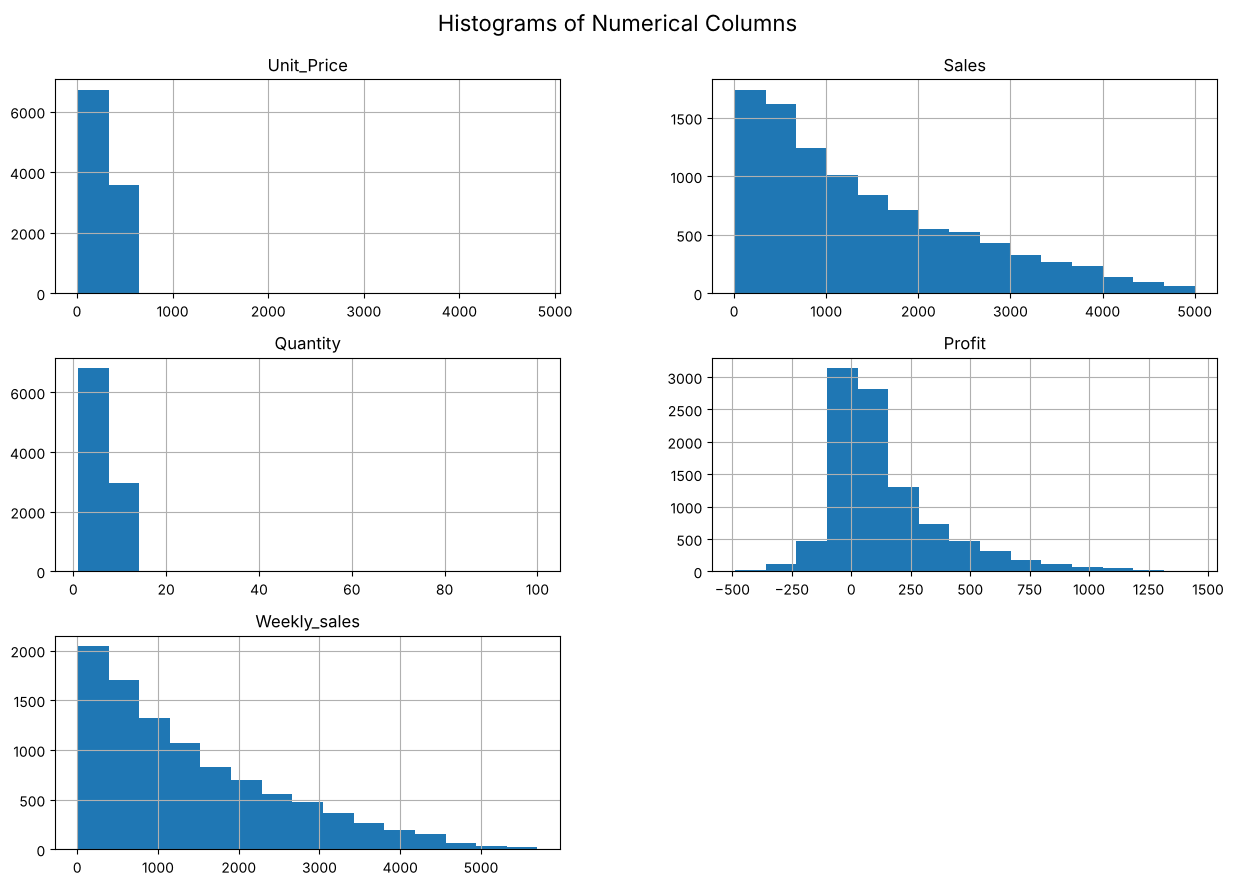

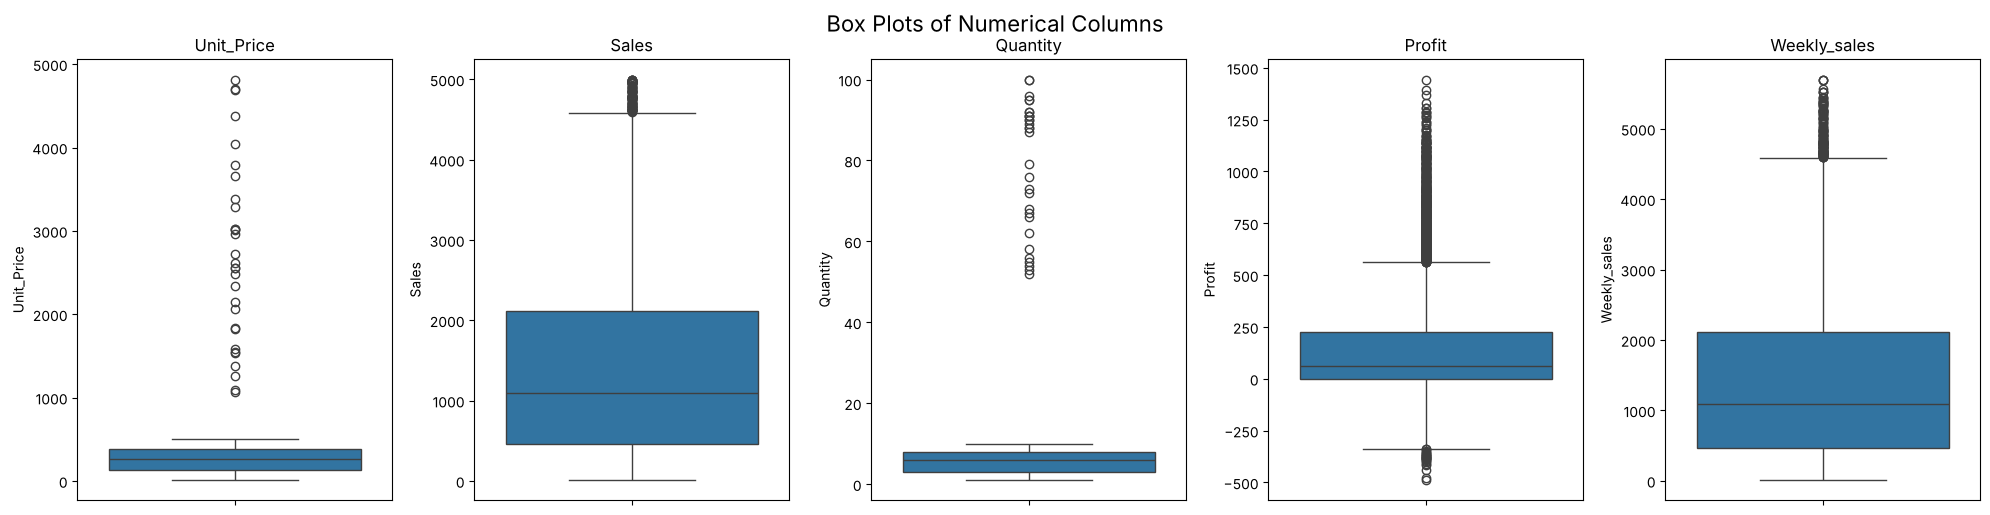

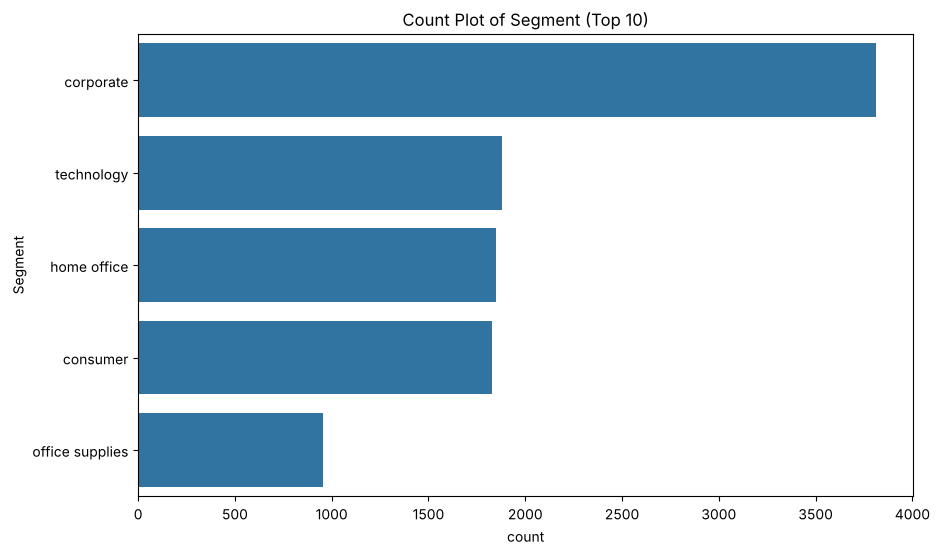

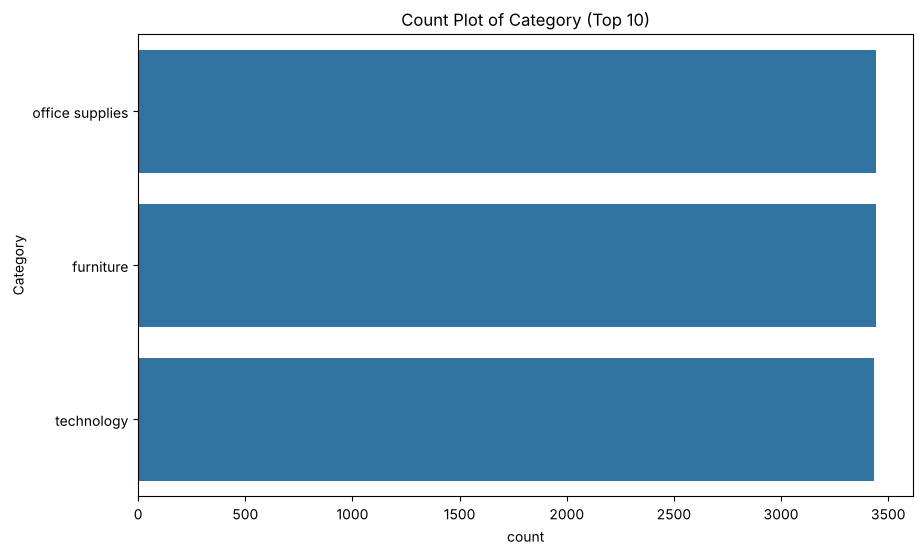

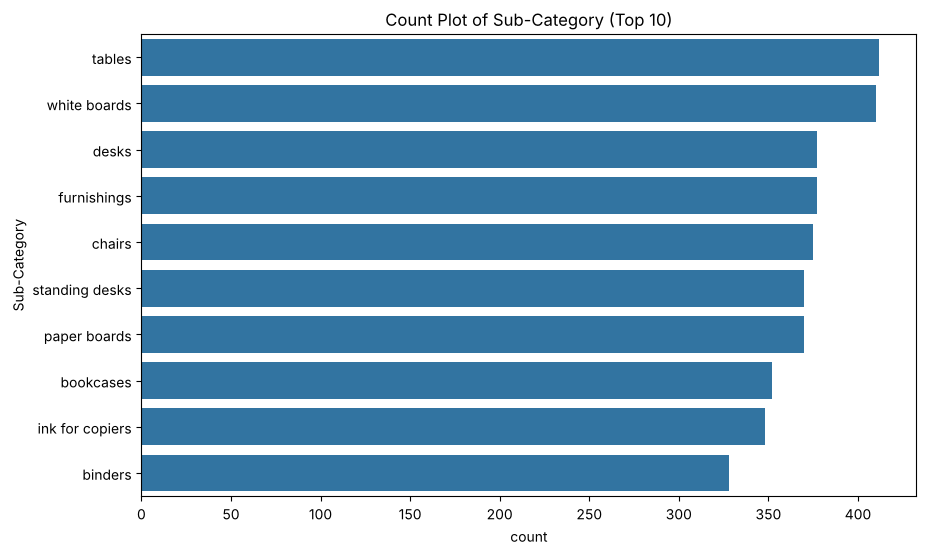

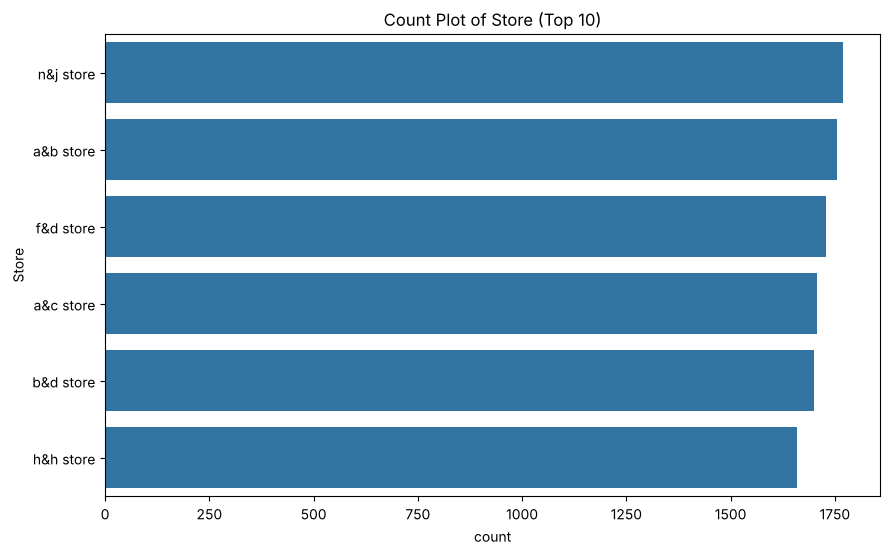

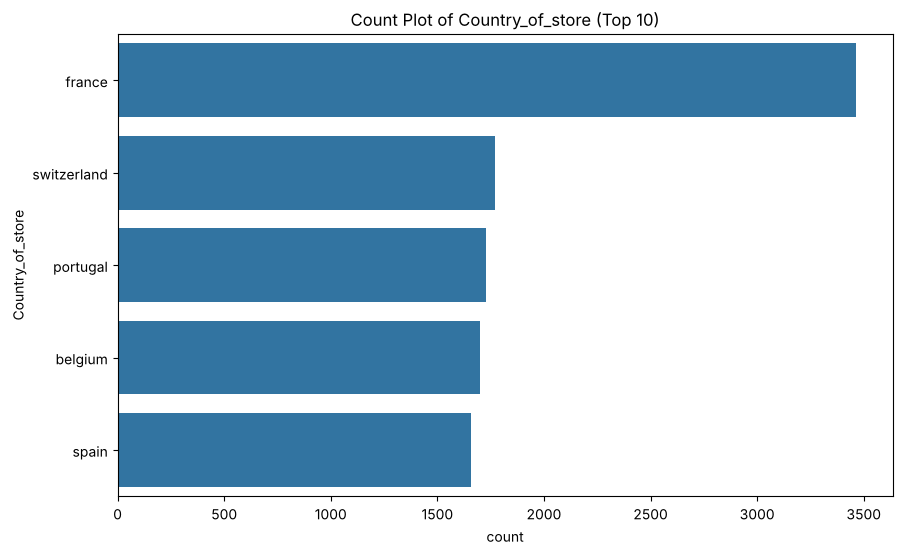

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Stats descriptives
print("Statistiques descriptives pour les variables numériques:")
display(df.describe())

# Counts des valeurs pour les variables catégorielles (top 10)
print("\nValue Counts for Categorical Columns (Top 10):")
for col in ['Segment', 'Category', 'Sub-Category', 'Store', 'Country_of_store']:
    if col in df.columns:
        print(f"\n{col}:")
        display(df[col].value_counts().head(10))

# Histogrammes pour les colonnes numériques
numerical_cols = ['Unit_Price', 'Sales', 'Quantity', 'Profit', 'Weekly_sales']
df[numerical_cols].hist(bins=15, figsize=(15, 10))
plt.suptitle("Histograms of Numerical Columns", y=0.95, fontsize=16)
plt.show()

# Box plots for numerical columns to identify outliers
fig, axes = plt.subplots(nrows=1, ncols=len(numerical_cols), figsize=(20, 5))
for i, col in enumerate(numerical_cols):
    sns.boxplot(y=df[col], ax=axes[i])
    axes[i].set_title(col)
plt.tight_layout()
plt.suptitle("Box Plots of Numerical Columns", y=1.02, fontsize=16)
plt.show()

# Count plots for categorical columns (top 10)
categorical_cols = ['Segment', 'Category', 'Sub-Category', 'Store', 'Country_of_store']
for col in categorical_cols:
    if col in df.columns:
        plt.figure(figsize=(10, 6))
        sns.countplot(y=col, data=df, order=df[col].value_counts().index[:10])
        plt.title(f"Count Plot of {col} (Top 10)")
        plt.show()

## Identifier les valeurs manquantes

Détecter et visualiser les valeurs manquantes dans chaque colonne du DataFrame.


In [5]:
missing_values_count = df.isnull().sum()
print("Nombre de valeurs manquantes par colonne:")
display(missing_values_count)

missing_values_percentage = (df.isnull().sum() / len(df)) * 100
print("\nPourcentage de valeurs manquantes par colonne:")
display(missing_values_percentage)

Nombre de valeurs manquantes par colonne:


Order_ID               0
Order_Date             0
Ship_Date              0
Customer_Name          0
Segment                0
Product_ID             0
Product_Name           0
Category               0
Sub-Category        1048
Unit_Price             0
Sales                505
Quantity             504
Profit               505
Store                  0
Country_of_store       0
Weekly_sales         505
dtype: int64


Pourcentage de valeurs manquantes par colonne:


Order_ID             0.000000
Order_Date           0.000000
Ship_Date            0.000000
Customer_Name        0.000000
Segment              0.000000
Product_ID           0.000000
Product_Name         0.000000
Category             0.000000
Sub-Category        10.155039
Unit_Price           0.000000
Sales                4.893411
Quantity             4.883721
Profit               4.893411
Store                0.000000
Country_of_store     0.000000
Weekly_sales         4.893411
dtype: float64

## Analyser les valeurs manquantes

### A FAIRE:
Déterminer l'étendue et le type des valeurs manquantes pour décider de la meilleure stratégie de traitement.


In [6]:
print("Data types of columns with missing values:")
print(df[['Sub-Category', 'Sales', 'Quantity', 'Profit', 'Weekly_sales']].dtypes)

Data types of columns with missing values:
Sub-Category     object
Sales           float64
Quantity        float64
Profit          float64
Weekly_sales    float64
dtype: object


* **'Sub-Category' is an object (variable catégorielle) avec ~10% de valeurs manquantes**
*  Imputation avec le mode ou une catégorie 'Unknown' sont nos options.
*  Supprimer les colonnes peut causer une perte importante de données
*  stratégie pour 'Sub-Category': imputation avec "mode" ou "unknown"

* **'Sales', 'Quantity', 'Profit', et 'Weekly_sales' sont float64 (numerical) avec ~5% des NA**
* Imputation avec moyenne ou médiane. médiane est plus robuste aux outliers
* Supprimer les NA va causer une perte de 5% des données, ce qui pourrait êtreacceptable selon les données.
* Strategy pour 'Sales', 'Quantity', 'Profit', 'Weekly_sales': imputation avec la médiane

## Traiter les valeurs manquantes

###  a faire :
Appliquer des méthodes appropriées pour gérer les valeurs manquantes


In [7]:
sub_category_mode = df['Sub-Category'].mode()[0]
df['Sub-Category'] = df['Sub-Category'].fillna(sub_category_mode) # ('unknown')


df['Sales'] = df['Sales'].fillna(df['Sales'].median())

quantity_median = df['Quantity'].median()
df['Quantity'] = df['Quantity'].fillna(quantity_median)

profit_median = df['Profit'].median()
df['Profit'] = df['Profit'].fillna(profit_median)

weekly_sales_median = df['Weekly_sales'].median()
df['Weekly_sales'] = df['Weekly_sales'].fillna(weekly_sales_median)

print("Missing values after imputation:")
display(df.isnull().sum())

Missing values after imputation:


Order_ID            0
Order_Date          0
Ship_Date           0
Customer_Name       0
Segment             0
Product_ID          0
Product_Name        0
Category            0
Sub-Category        0
Unit_Price          0
Sales               0
Quantity            0
Profit              0
Store               0
Country_of_store    0
Weekly_sales        0
dtype: int64

## Identifier les doublons

### a faire :
Détecter les lignes en double dans le DataFrame.


In [8]:
duplicate_rows = df.duplicated()
num_duplicate_rows = duplicate_rows.sum()
print(f"Number of duplicate rows: {num_duplicate_rows}")

print("\nFirst 5 duplicate rows:")
display(df[duplicate_rows].head())

Number of duplicate rows: 58

First 5 duplicate rows:


,Order_ID,Order_Date,Ship_Date,Customer_Name,Segment,Product_ID,Product_Name,Category,Sub-Category,Unit_Price,Sales,Quantity,Profit,Store,Country_of_store,Weekly_sales
272,ORD-8898,2023-03-10,2023-03-16,Innovate Ltd,corporate,PROD-6508,Recycled Paper,office supplies,paper,261.16,261.16,1.0,53.41,b&d store,belgium,233.28
564,ORD-9159,2024-02-22,2024-02-24,Business Solutions,corporate,PROD-8855,Ergonomic Chair,furniture,chairs,465.02,1099.98,6.0,63.60,b&d store,belgium,1093.23
1071,ORD-9047,2023-07-21,2023-07-24,Business Solutions,corporate,PROD-1832,Generic Product,office supplies,supplies,334.77,2678.16,8.0,140.55,n&j store,switzerland,3211.29
1486,ORD-5529,2024-07-26,2024-07-28,TechnoCorp,technology,PROD-3321,Binder X100,office supplies,binders,330.41,2643.28,8.0,52.86,f&d store,portugal,2663.19
1978,ORD-9555,2023-09-25,2023-09-28,Business Solutions,corporate,PROD-7981,Generic Product,office supplies,markers,256.37,512.74,2.0,87.38,n&j store,switzerland,440.41


## Analyser les doublons

### Subtask:
Examiner les lignes en double pour comprendre leur nature et leur impact potentiel.


In [9]:
print(f"Number of duplicate rows: {num_duplicate_rows}")

print("\nFirst 5 duplicate rows:")
display(df[duplicate_rows].head())

Number of duplicate rows: 58

First 5 duplicate rows:


,Order_ID,Order_Date,Ship_Date,Customer_Name,Segment,Product_ID,Product_Name,Category,Sub-Category,Unit_Price,Sales,Quantity,Profit,Store,Country_of_store,Weekly_sales
272,ORD-8898,2023-03-10,2023-03-16,Innovate Ltd,corporate,PROD-6508,Recycled Paper,office supplies,paper,261.16,261.16,1.0,53.41,b&d store,belgium,233.28
564,ORD-9159,2024-02-22,2024-02-24,Business Solutions,corporate,PROD-8855,Ergonomic Chair,furniture,chairs,465.02,1099.98,6.0,63.60,b&d store,belgium,1093.23
1071,ORD-9047,2023-07-21,2023-07-24,Business Solutions,corporate,PROD-1832,Generic Product,office supplies,supplies,334.77,2678.16,8.0,140.55,n&j store,switzerland,3211.29
1486,ORD-5529,2024-07-26,2024-07-28,TechnoCorp,technology,PROD-3321,Binder X100,office supplies,binders,330.41,2643.28,8.0,52.86,f&d store,portugal,2663.19
1978,ORD-9555,2023-09-25,2023-09-28,Business Solutions,corporate,PROD-7981,Generic Product,office supplies,markers,256.37,512.74,2.0,87.38,n&j store,switzerland,440.41


## Traiter les doublons

### a faire:
Supprimer les lignes en double du DataFrame.


In [10]:
df.drop_duplicates(inplace=True)
num_duplicate_rows_after_removal = df.duplicated().sum()
print(f"Number of duplicate rows after removal: {num_duplicate_rows_after_removal}")

Number of duplicate rows after removal: 0


## Traiter les outliers

In [11]:
# Utiliser la méthode IQR pour le traitement des valeurs abberantes
numerical_cols = ['Unit_Price', 'Sales', 'Quantity', 'Profit', 'Weekly_sales']

for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # on va faire un cap sur les outliers
    df[col] = df[col].clip(lower=lower_bound, upper=upper_bound)

print("traitement des outliers pour les col numériques.")
display(df[numerical_cols].describe())

traitement des outliers pour les col numériques.


,Unit_Price,Sales,Quantity,Profit,Weekly_sales
count,10262.000000,10262.000000,10262.000000,10262.000000,10262.000000
mean,256.691851,1393.544857,5.582148,120.908941,1390.879443
std,142.887705,1104.778670,2.851740,187.321143,1113.620995
min,10.120000,10.240000,1.000000,-316.477500,9.280000
25%,133.177500,484.417500,3.000000,1.530000,484.765000
50%,257.470000,1099.980000,6.000000,63.600000,1093.230000
75%,377.902500,2043.782500,8.000000,213.535000,2043.417500
max,744.990000,4382.830000,15.500000,531.542500,4381.396250


## Vérifier les résultats

###  pourquoi ?
S'assurer que les valeurs manquantes et les doublons ont été traités correctement

In [12]:
missing_values_count_after = df.isnull().sum()
print("Number of missing values after cleaning:")
display(missing_values_count_after)

num_duplicate_rows_after = df.duplicated().sum()
print(f"\nNumber of duplicate rows after cleaning: {num_duplicate_rows_after}")

Number of missing values after cleaning:


Order_ID            0
Order_Date          0
Ship_Date           0
Customer_Name       0
Segment             0
Product_ID          0
Product_Name        0
Category            0
Sub-Category        0
Unit_Price          0
Sales               0
Quantity            0
Profit              0
Store               0
Country_of_store    0
Weekly_sales        0
dtype: int64


Number of duplicate rows after cleaning: 0


## Visualiser l'impact du traitement sur les variables

stats descriptives pour les colonnes numériques:


,Order_Date,Ship_Date,Unit_Price,Sales,Quantity,Profit,Weekly_sales
count,10262,10262,10262.000000,10262.000000,10262.000000,10262.000000,10262.000000
mean,2024-02-10 21:09:05.156889,2024-02-16 08:09:01.648801,256.691851,1393.544857,5.582148,120.908941,1390.879443
min,2023-02-12 00:00:00,2023-02-13 00:00:00,10.120000,10.240000,1.000000,-316.477500,9.280000
25%,2023-08-12 00:00:00,2023-08-18 00:00:00,133.177500,484.417500,3.000000,1.530000,484.765000
50%,2024-02-13 00:00:00,2024-02-19 00:00:00,257.470000,1099.980000,6.000000,63.600000,1093.230000
75%,2024-08-08 00:00:00,2024-08-13 00:00:00,377.902500,2043.782500,8.000000,213.535000,2043.417500
max,2025-02-10 00:00:00,2025-02-19 00:00:00,744.990000,4382.830000,15.500000,531.542500,4381.396250
std,NaN,NaN,142.887705,1104.778670,2.851740,187.321143,1113.620995



Counts des valeurs pour les variables catégorielles (Top 10):

Segment:


Segment
corporate          3786
technology         1871
home office        1834
consumer           1822
office supplies     949
Name: count, dtype: int64


Category:


...

Sub-Category
tables             1447
white boards        408
desks               377
furnishings         375
chairs              372
standing desks      370
paper boards        367
bookcases           349
ink for copiers     347
accessories         325
Name: count, dtype: int64


Store:


Store
n&j store    1758
a&b store    1744
f&d store    1721
a&c store    1699
b&d store    1689
h&h store    1651
Name: count, dtype: int64


Country_of_store:


Country_of_store
france         3443
switzerland    1758
portugal       1721
belgium        1689
spain          1651
Name: count, dtype: int64

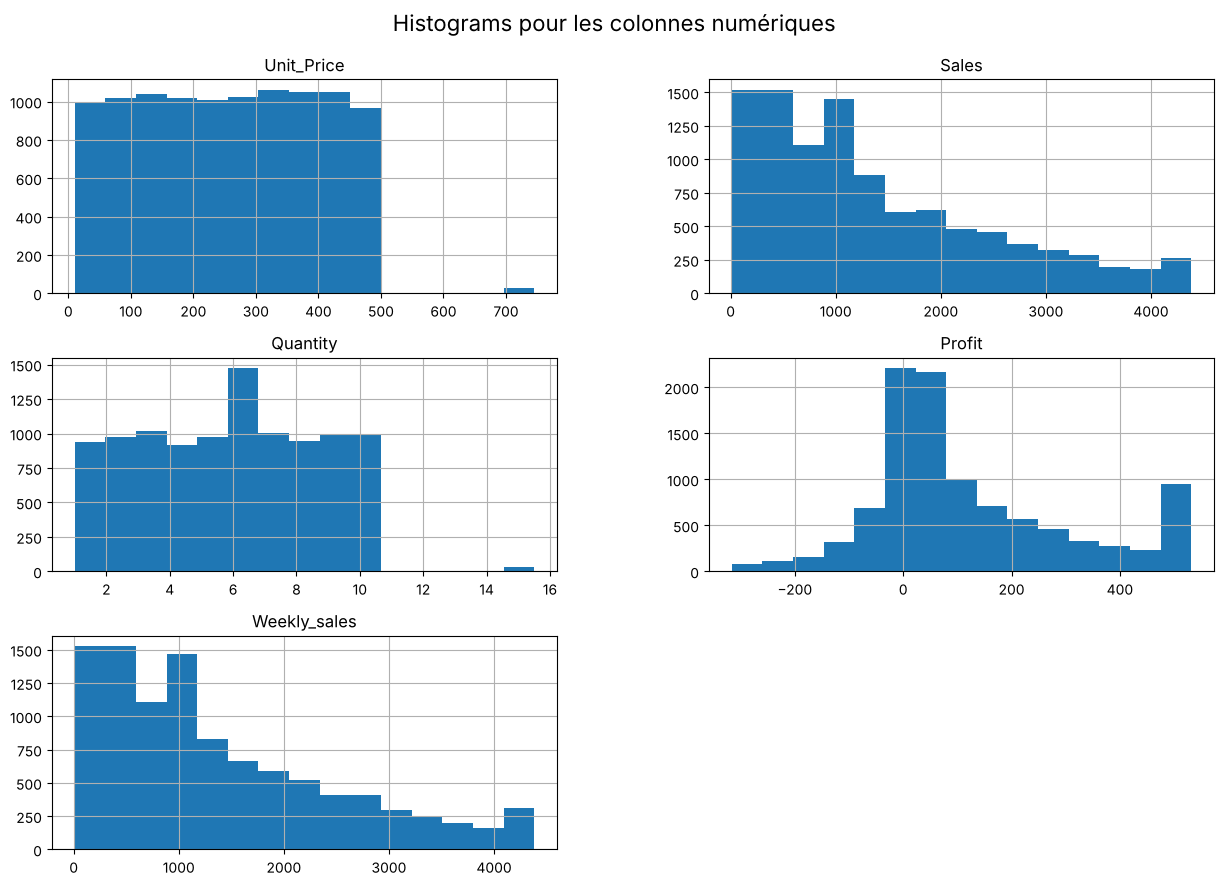

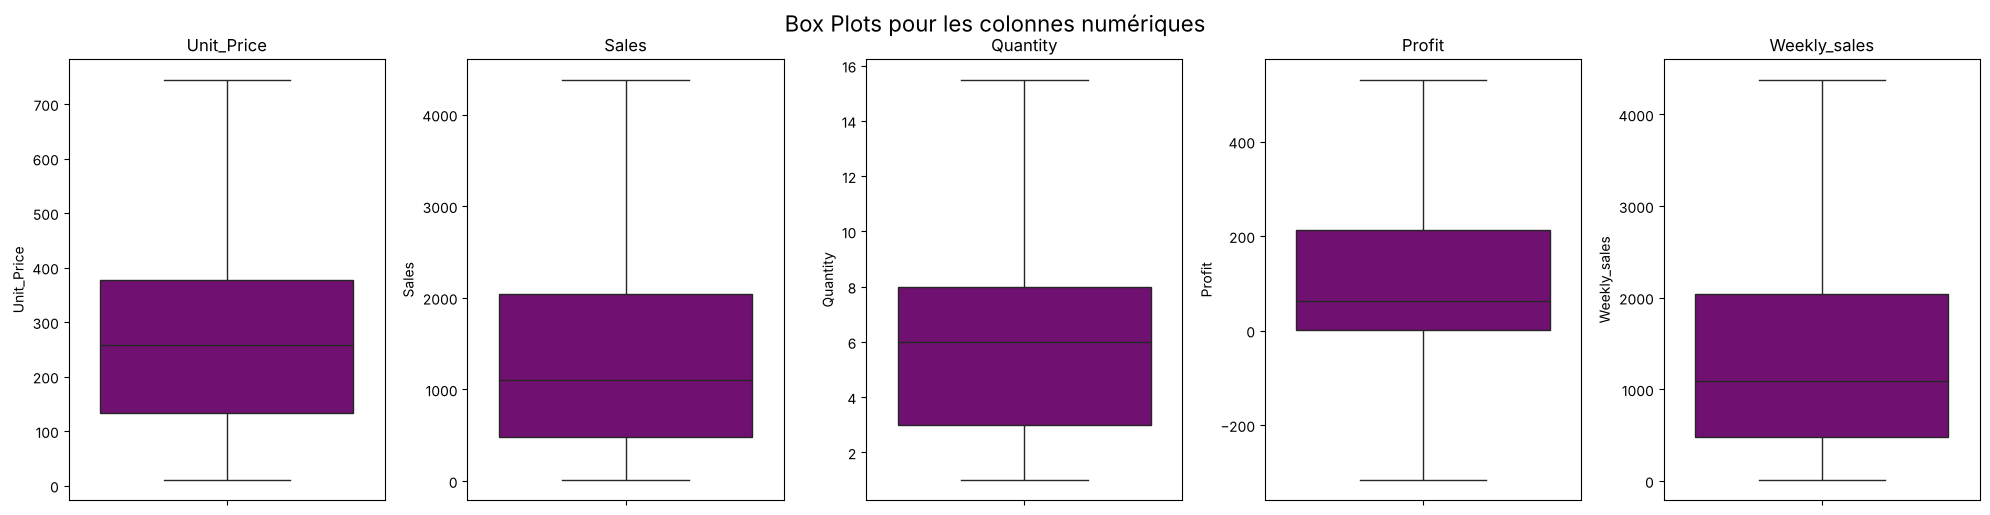

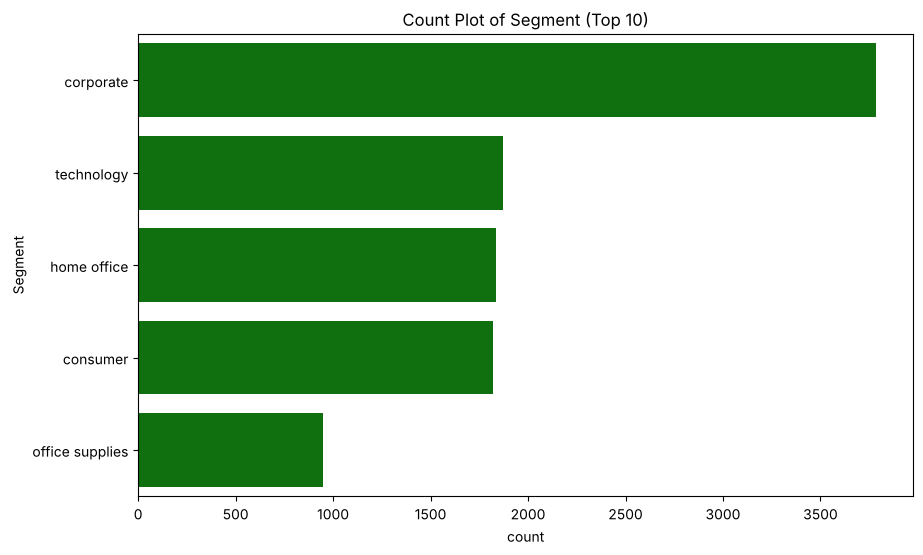

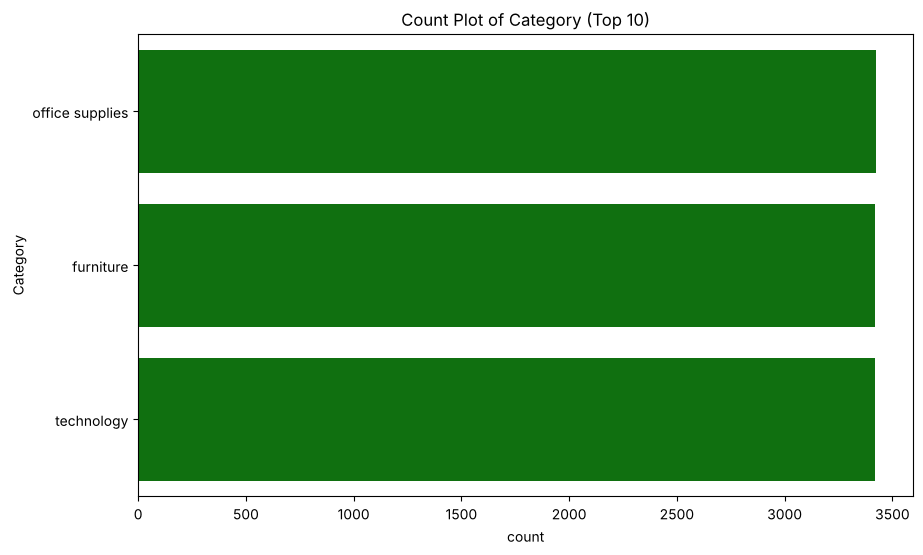

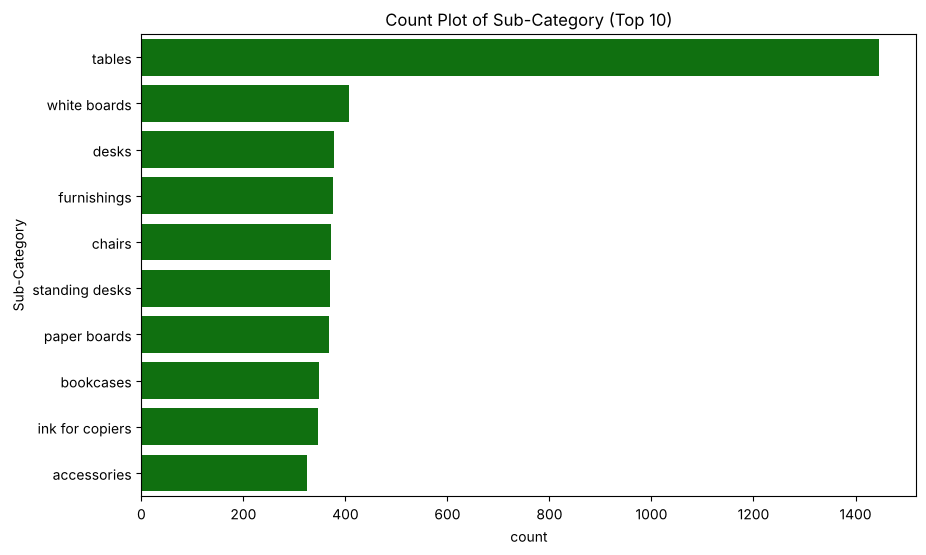

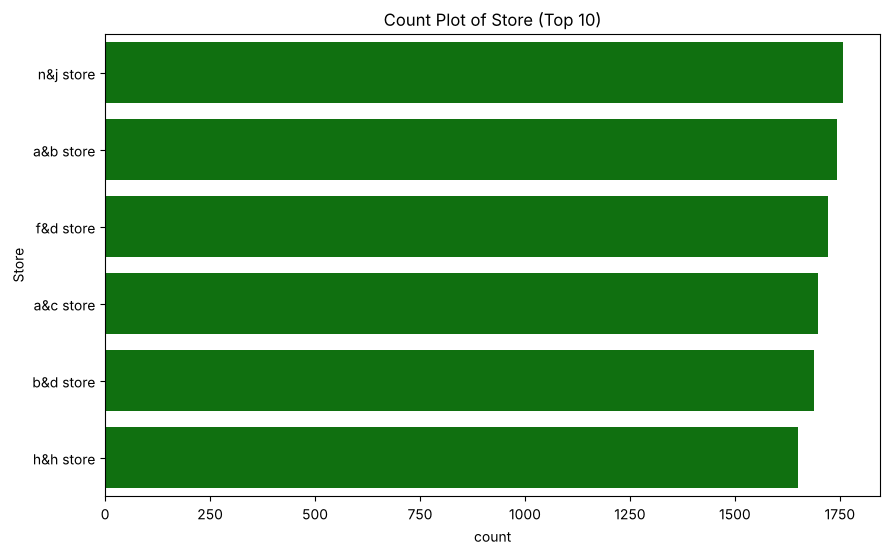

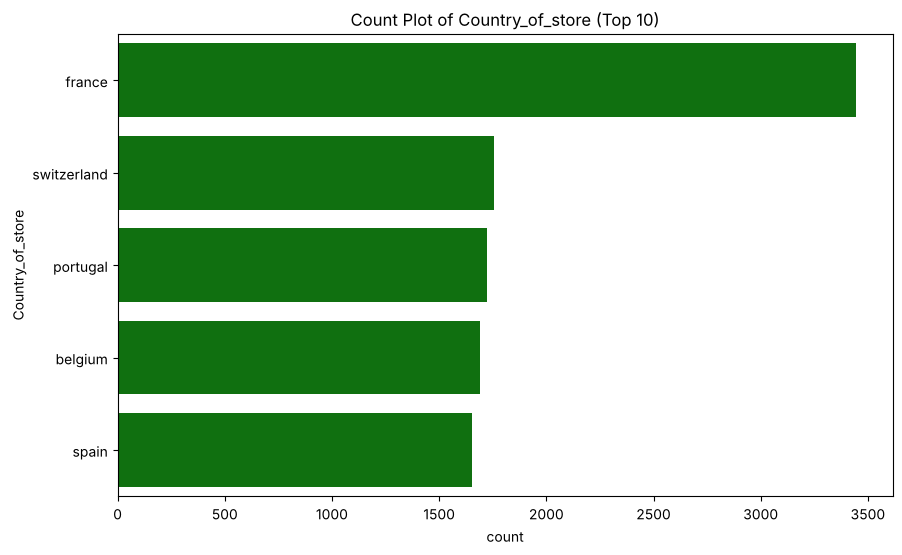

In [13]:
# Descriptive statistics for numerical columns
print("stats descriptives pour les colonnes numériques:")
display(df.describe())

# Value counts for categorical columns (top 10)
print("\nCounts des valeurs pour les variables catégorielles (Top 10):")
for col in ['Segment', 'Category', 'Sub-Category', 'Store', 'Country_of_store']:
    if col in df.columns:
        print(f"\n{col}:")
        display(df[col].value_counts().head(10))

# Histograms for numerical columns
numerical_cols = ['Unit_Price', 'Sales', 'Quantity', 'Profit', 'Weekly_sales']
df[numerical_cols].hist(bins=15, figsize=(15, 10))
plt.suptitle("Histograms pour les colonnes numériques", y=0.95, fontsize=16)
plt.show()

# Box plots for numerical columns to identify outliers
fig, axes = plt.subplots(nrows=1, ncols=len(numerical_cols), figsize=(20, 5))
for i, col in enumerate(numerical_cols):
    sns.boxplot(y=df[col], ax=axes[i], color='purple')
    axes[i].set_title(col)
plt.tight_layout()
plt.suptitle("Box Plots pour les colonnes numériques", y=1.02, fontsize=16)
plt.show()

# Count plots for categorical columns (top 10)
categorical_cols = ['Segment', 'Category', 'Sub-Category', 'Store', 'Country_of_store']
for col in categorical_cols:
    if col in df.columns:
        plt.figure(figsize=(10, 6))
        sns.countplot(y=col, data=df, order=df[col].value_counts().index[:10], color='green')
        plt.title(f"Count Plot of {col} (Top 10)")
        plt.show()

# Step 2 : Visualisations bivariées et multivariées

In [14]:
# Prérequis : pip install -r requirements.txt (scipy est utilisé pour les tests statistiques)

In [15]:
from scipy import stats
import warnings
import numpy as np
warnings.filterwarnings('ignore')

In [16]:
def numerical_vs_categorical(df, numerical_col, categorical_col):
    """Analyse relation entre variable numérique et catégorielle"""

    fig, axes = plt.subplots(2, 2, figsize=(15, 10))

    # Boxplot par categorie
    df.boxplot(column=numerical_col, by=categorical_col, ax=axes[0,0])
    axes[0,0].set_title(f'{numerical_col} par {categorical_col}')
    axes[0,0].tick_params(axis='x', rotation=45)

    # Violin plot
    categories = df[categorical_col].unique()
    data_to_plot = [df[df[categorical_col] == cat][numerical_col].dropna() for cat in categories]
    axes[0,1].violinplot(data_to_plot)
    axes[0,1].set_xticks(range(1, len(categories) + 1))
    axes[0,1].set_xticklabels(categories, rotation=45)
    axes[0,1].set_title(f'Distribution de {numerical_col} par {categorical_col}')

    # Barplot des moyennes
    means = df.groupby(categorical_col)[numerical_col].mean().sort_values(ascending=False)
    axes[1,0].bar(range(len(means)), means.values, color='lightgreen')
    axes[1,0].set_xticks(range(len(means)))
    axes[1,0].set_xticklabels(means.index, rotation=45)
    axes[1,0].set_title(f'Moyenne de {numerical_col} par {categorical_col}')

    # ANOVA test
    groups = [df[df[categorical_col] == cat][numerical_col].dropna() for cat in categories]
    f_stat, p_value = stats.f_oneway(*groups)

    axes[1,1].text(0.1, 0.5, f"Test ANOVA\nF-statistic: {f_stat:.2f}\np-value: {p_value:.4f}",
                   fontsize=12, transform=axes[1,1].transAxes)
    axes[1,1].set_title('Test de Significativité')
    axes[1,1].axis('off')

    plt.suptitle(f'Relation entre {numerical_col} et {categorical_col}', fontsize=16)
    plt.tight_layout()
    plt.show()

    return f_stat, p_value

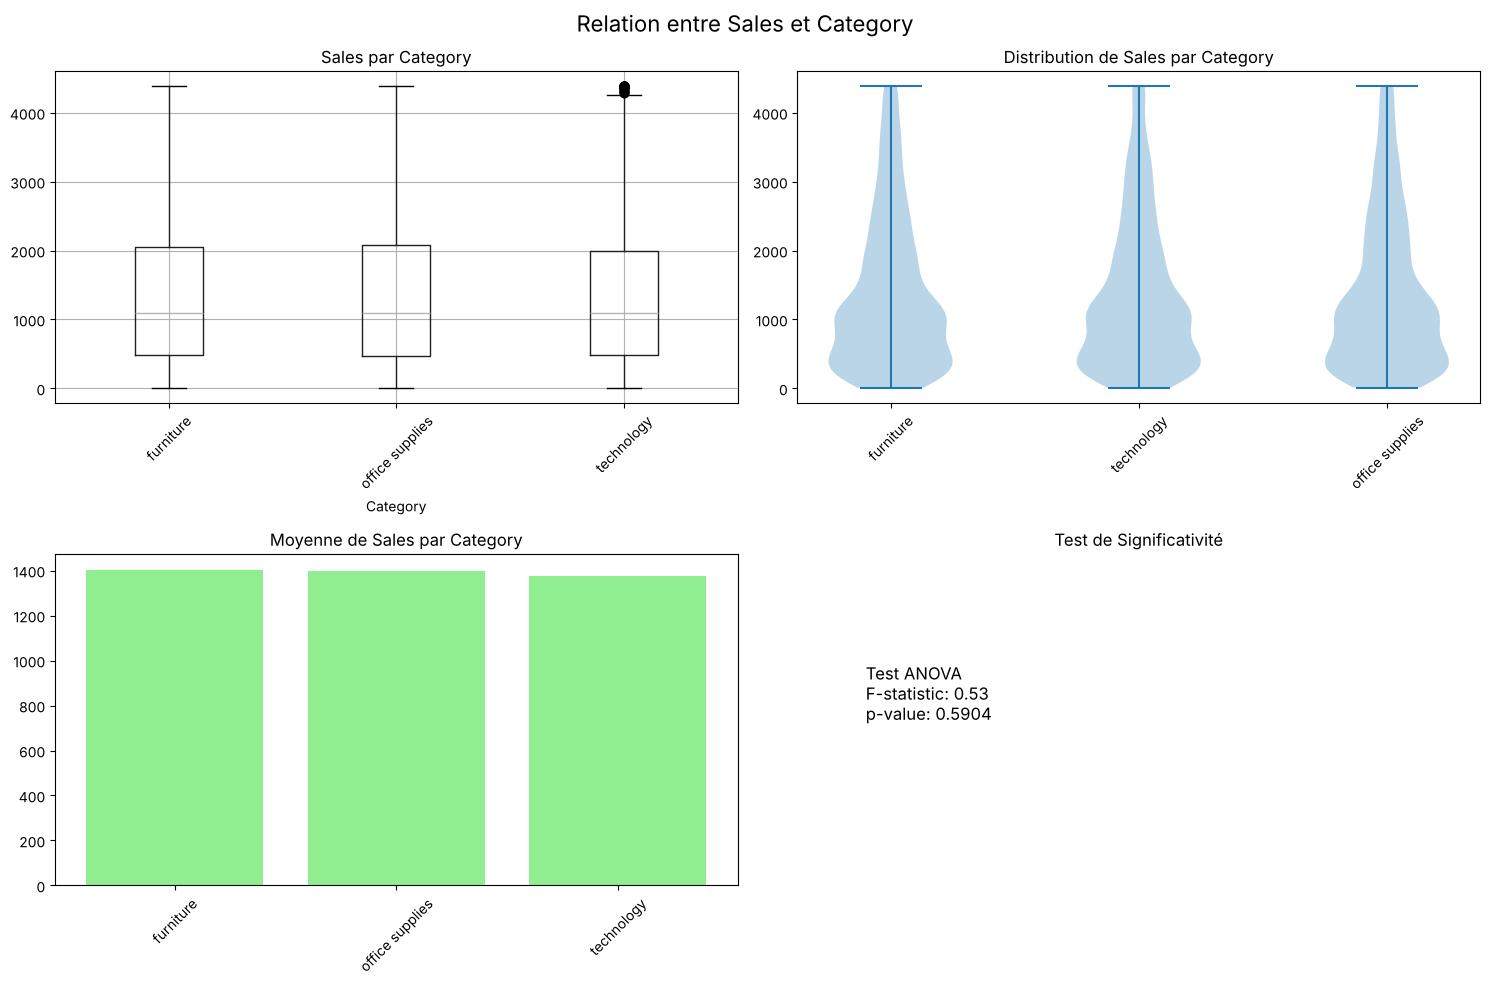

In [17]:
f_stat, p_value = numerical_vs_categorical(df, 'Sales', 'Category')

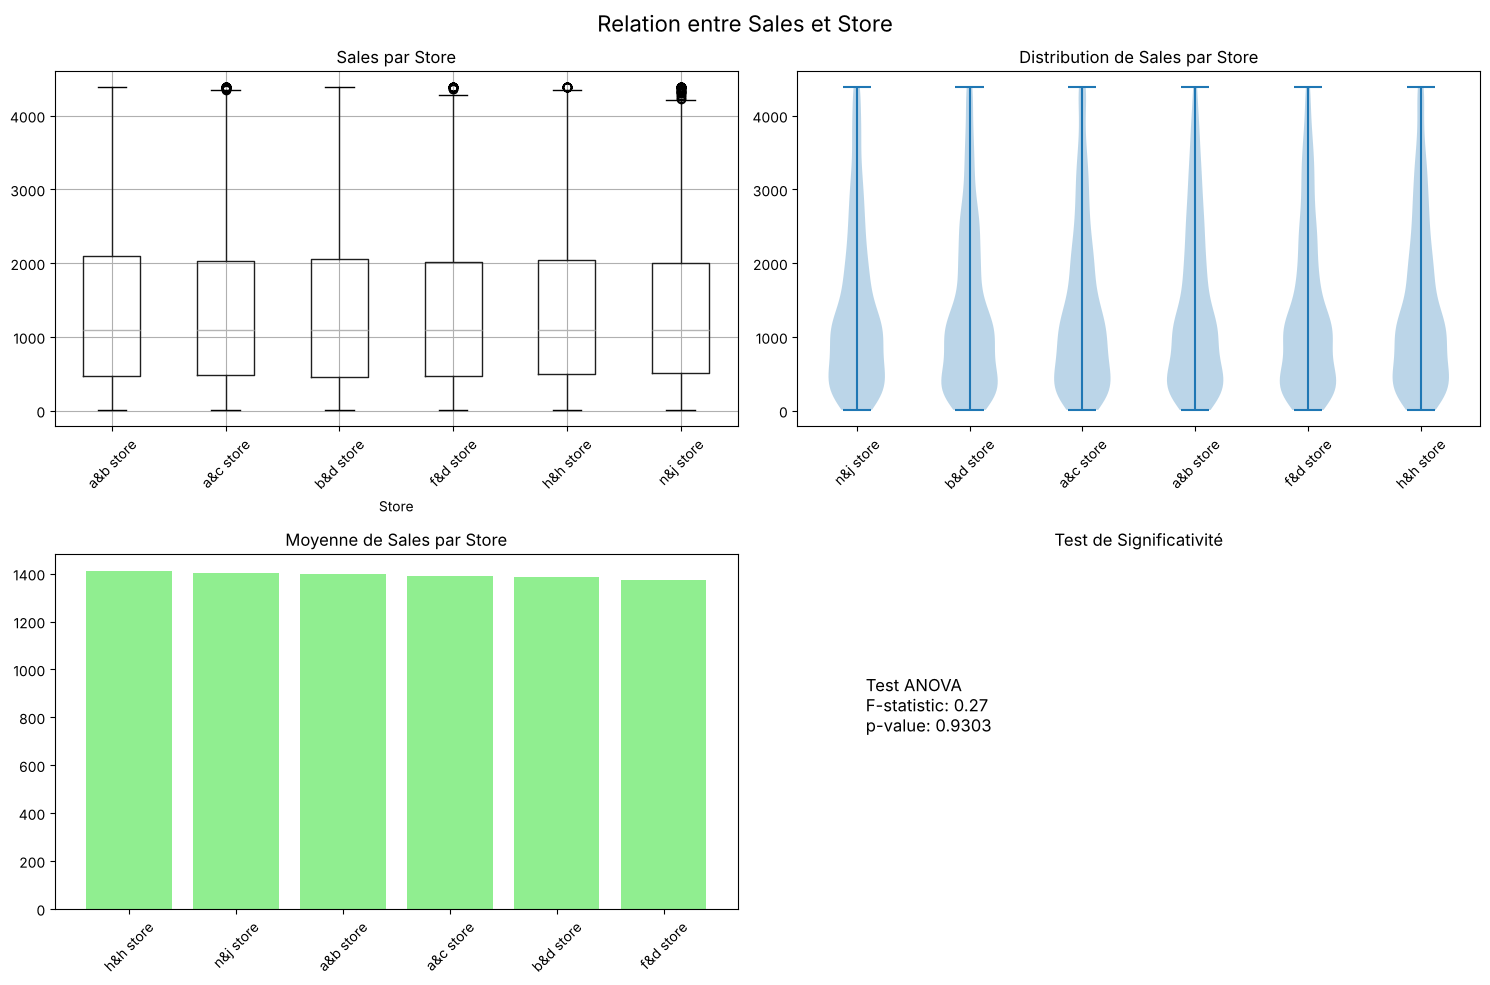

In [18]:
f_stat, p_value = numerical_vs_categorical(df, 'Sales', 'Store')

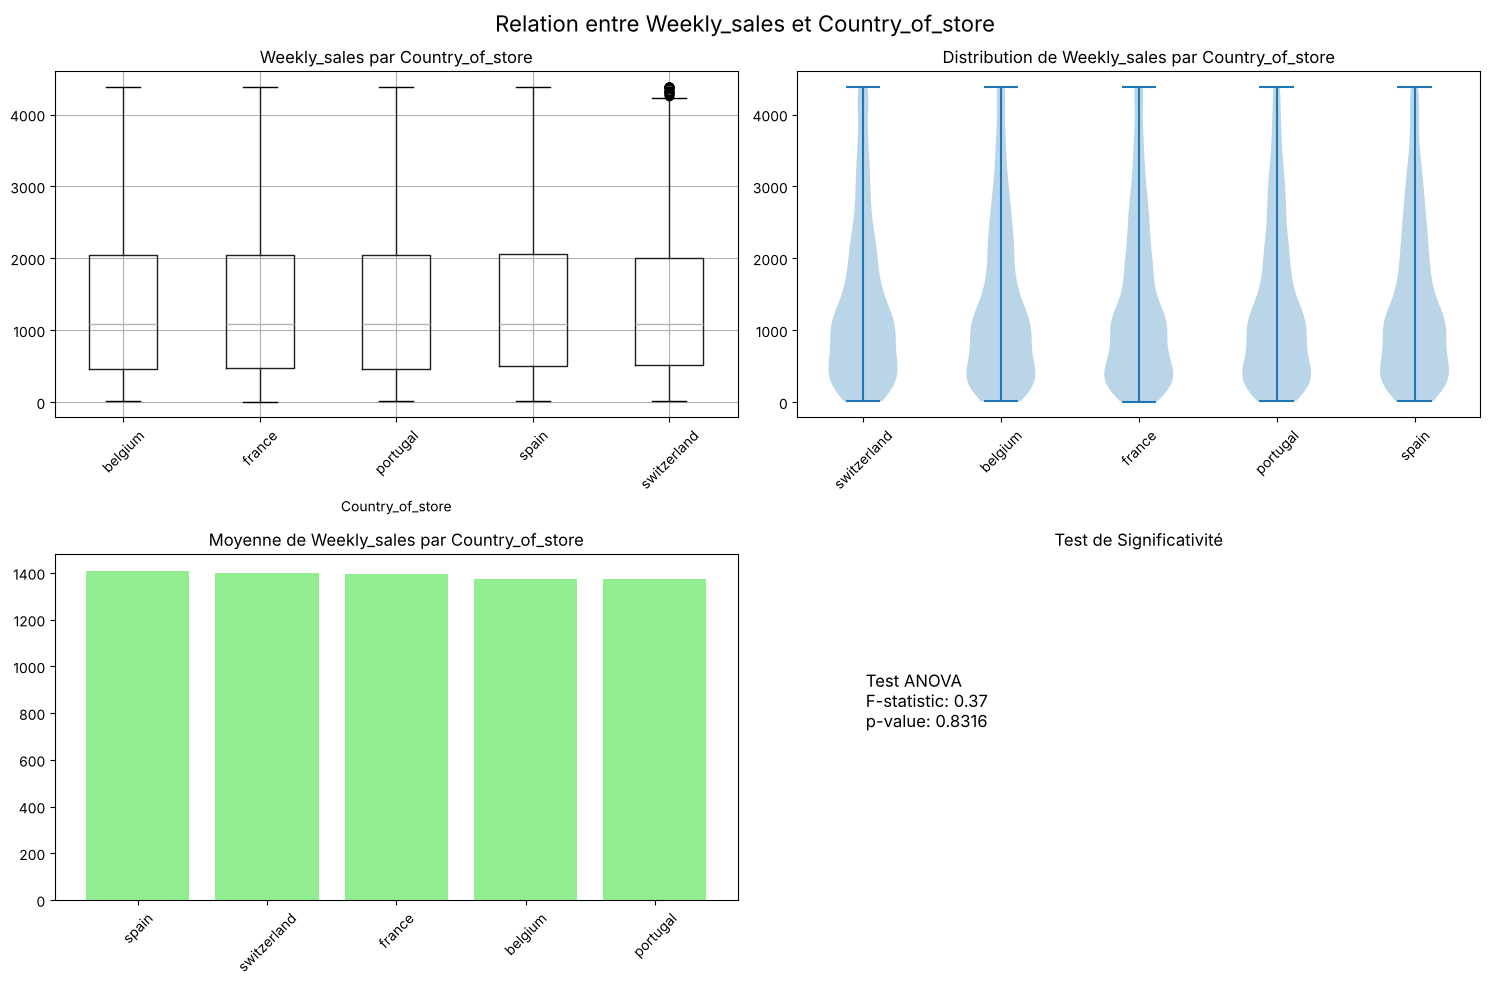

In [19]:
f_stat, p_value = numerical_vs_categorical(df, 'Weekly_sales', 'Country_of_store')

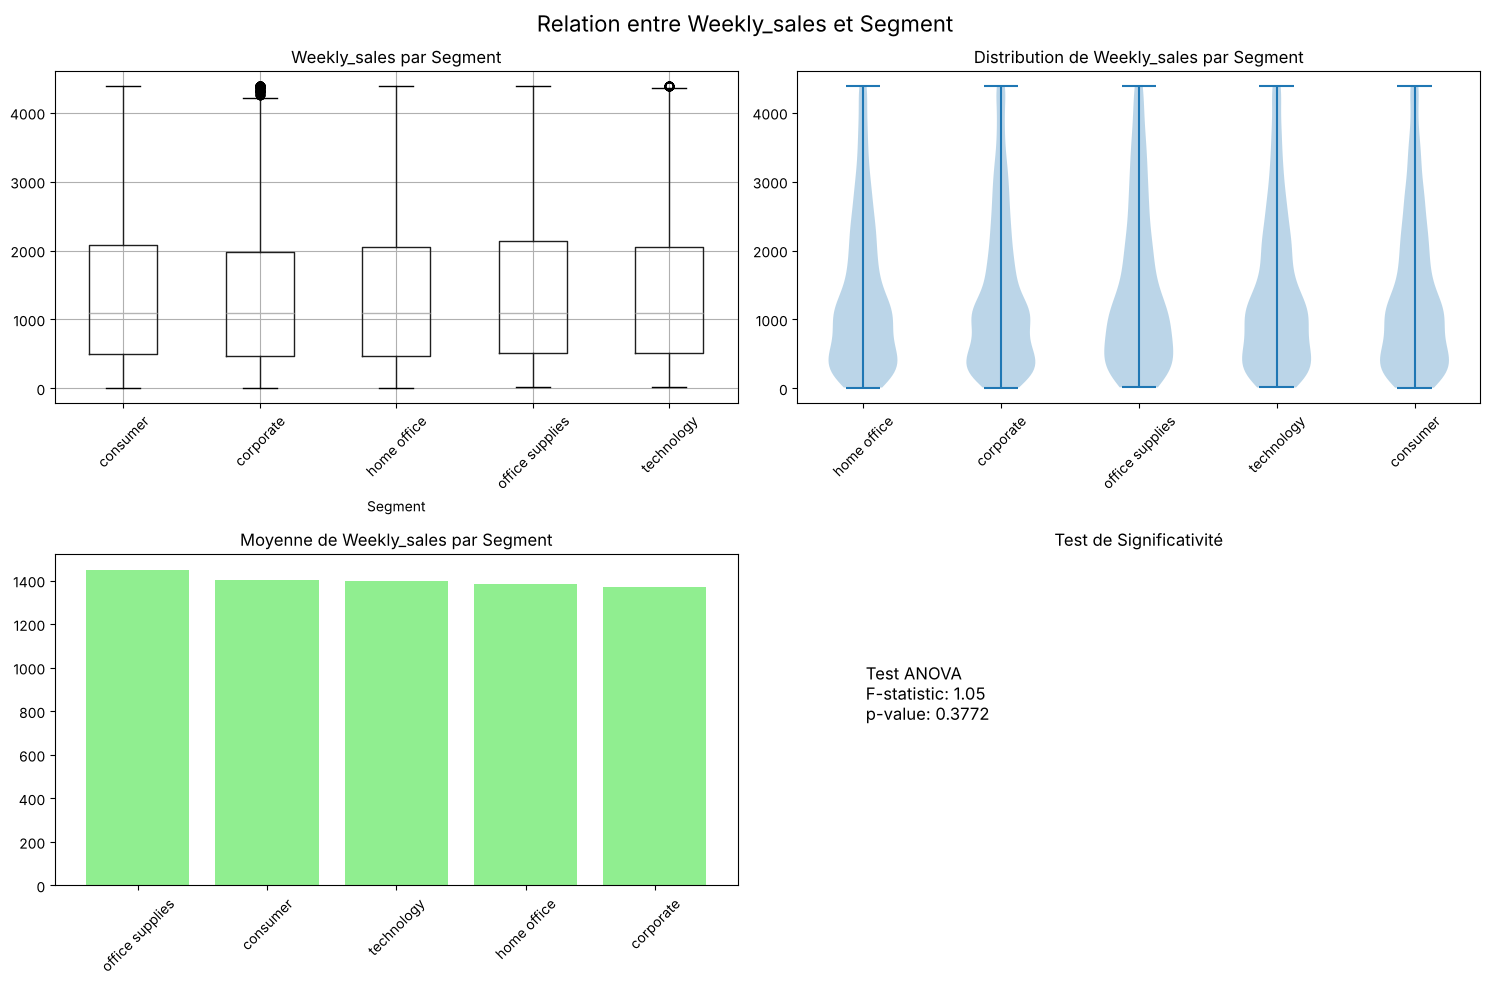

In [20]:
f_stat, p_value = numerical_vs_categorical(df, 'Weekly_sales', 'Segment')

In [21]:
def numerical_vs_numerical(df, num_cols):
    """Analyse des relations entre variables numériques"""

    # matrice de corrélation
    correlation_matrix = df[num_cols].corr()

    plt.figure(figsize=(12, 8))
    sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0,
                square=True, linewidths=0.5)
    plt.title('Matrice de Corrélation entre Variables Numériques', fontsize=16)
    plt.tight_layout()
    plt.show()

    # Scatter plots pour les paires les plus corrélées
    corr_pairs = []
    for i in range(len(correlation_matrix.columns)):
        for j in range(i+1, len(correlation_matrix.columns)):
            col1 = correlation_matrix.columns[i]
            col2 = correlation_matrix.columns[j]
            corr = correlation_matrix.iloc[i, j]
            corr_pairs.append((col1, col2, corr))

    # Trier par valeur absolue de corrélation
    corr_pairs.sort(key=lambda x: abs(x[2]), reverse=True)

    # Afficher les top correlations
    print("TOP CORRELATIONS")
    for col1, col2, corr in corr_pairs[:10]:
        print(f"{col1} vs {col2}: {corr:.3f}")

    # Scatter plots pour les top 4 paires
    top_pairs = corr_pairs[:4]
    if top_pairs:
        fig, axes = plt.subplots(2, 2, figsize=(15, 10))
        axes = axes.ravel()

        for idx, (col1, col2, corr) in enumerate(top_pairs):
            axes[idx].scatter(df[col1], df[col2], alpha=0.5)
            axes[idx].set_xlabel(col1)
            axes[idx].set_ylabel(col2)
            axes[idx].set_title(f'{col1} vs {col2}\n(corr: {corr:.3f})')

            # Ligne de régression
            if not df[[col1, col2]].isnull().any().any():
                z = np.polyfit(df[col1], df[col2], 1)
                p = np.poly1d(z)
                axes[idx].plot(df[col1], p(df[col1]), "r--", alpha=0.8)

        plt.tight_layout()
        plt.show()

    return correlation_matrix

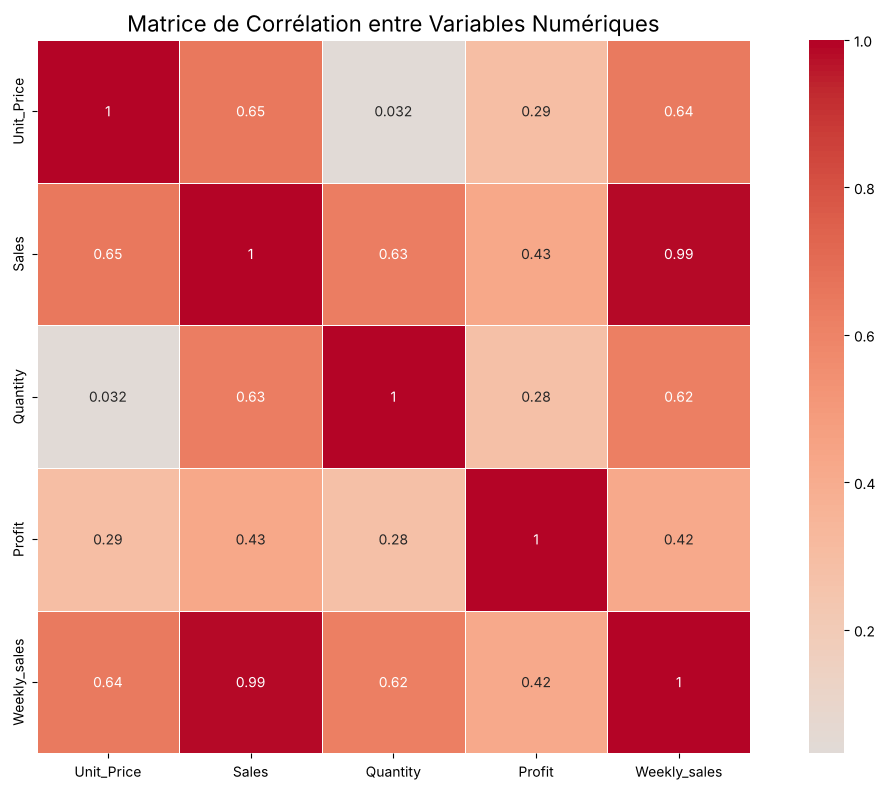

TOP CORRELATIONS
Sales vs Weekly_sales: 0.985
Unit_Price vs Sales: 0.653
Unit_Price vs Weekly_sales: 0.643
Sales vs Quantity: 0.627
Quantity vs Weekly_sales: 0.620
Sales vs Profit: 0.428
Profit vs Weekly_sales: 0.420
Unit_Price vs Profit: 0.293
Quantity vs Profit: 0.276
Unit_Price vs Quantity: 0.032


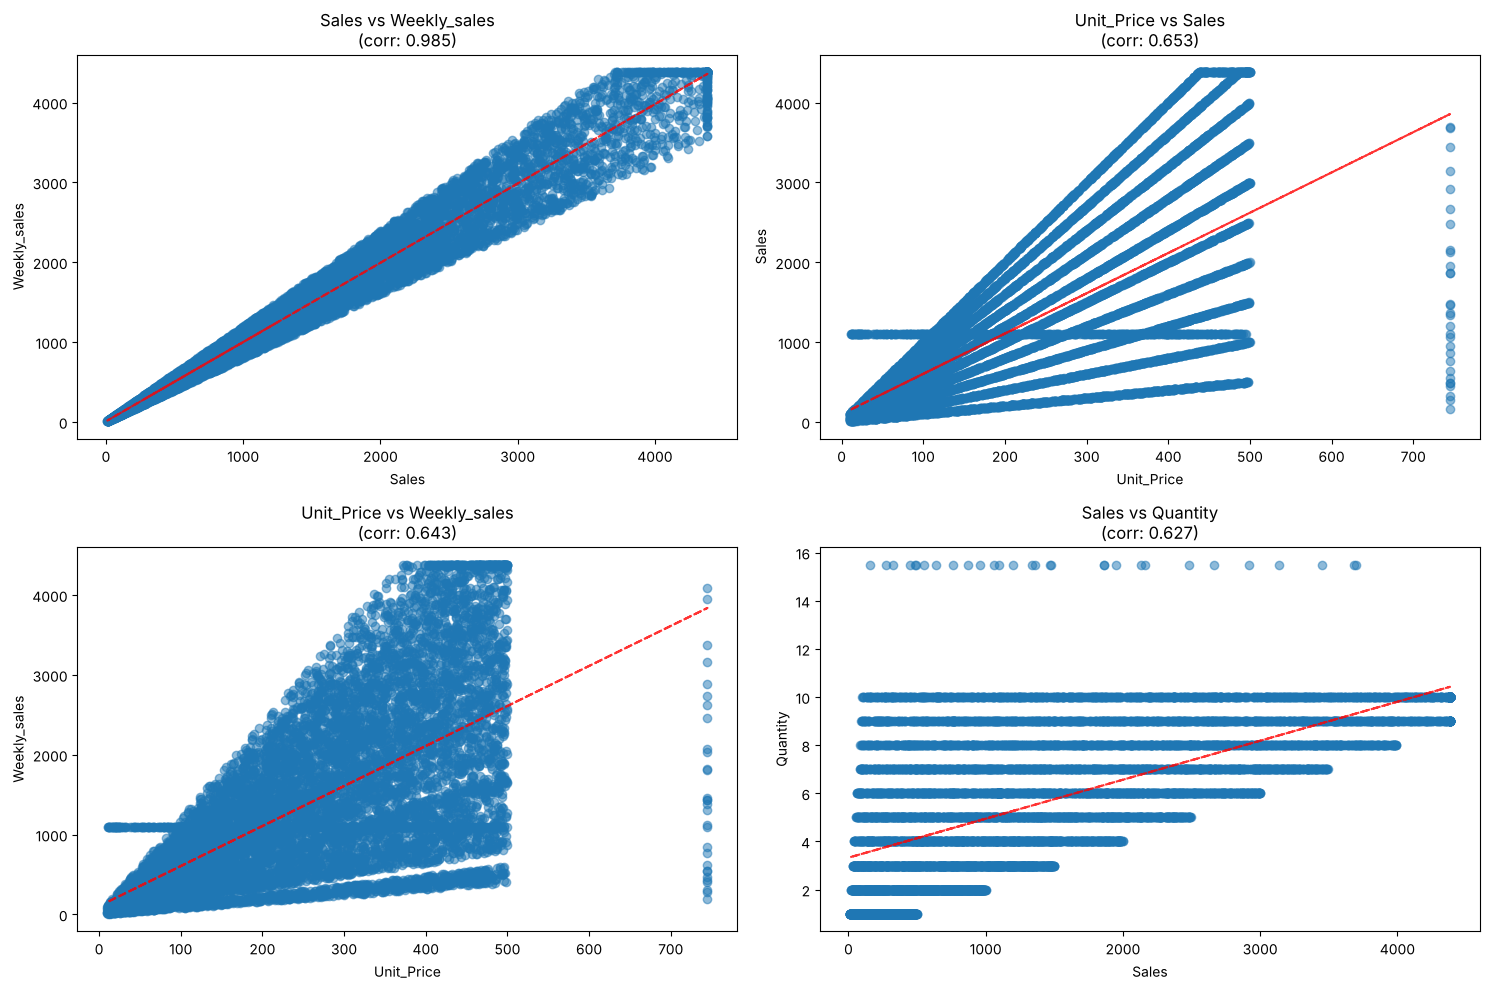

In [22]:
corr_matrix = numerical_vs_numerical(df, numerical_cols)

In [23]:
def categorical_vs_categorical(df, cat_col1, cat_col2):
    """Analyse croisée entre deux variables catégorielles"""

    # Table de contingence
    contingency_table = pd.crosstab(df[cat_col1], df[cat_col2], margins=True)

    fig, axes = plt.subplots(2, 2, figsize=(15, 12))

    # Heatmap de la table de contingence
    sns.heatmap(contingency_table.iloc[:-1, :-1], annot=True, fmt='d', cmap='YlOrRd', ax=axes[0,0])
    axes[0,0].set_title(f'Table de Contingence: {cat_col1} vs {cat_col2}')

    # Stacked bar chart
    cross_tab = pd.crosstab(df[cat_col1], df[cat_col2], normalize='index') * 100
    cross_tab.plot(kind='bar', stacked=True, ax=axes[0,1])
    axes[0,1].set_title(f'Répartition de {cat_col2} par {cat_col1} (%)')
    axes[0,1].legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    axes[0,1].tick_params(axis='x', rotation=45)

    # Test du Chi²
    chi2, p_value, dof, expected = stats.chi2_contingency(
        pd.crosstab(df[cat_col1], df[cat_col2])
    )

    # mosaic plot (simplifié)
    props = {}
    for i in range(len(cross_tab.index)):
        for j in range(len(cross_tab.columns)):
            props[(i, j)] = {'color': plt.cm.Set3(j / len(cross_tab.columns))}

    # Résultats des tests
    axes[1,0].axis('off')
    test_text = f"Test d'Indépendance Chi²\n\nChi² = {chi2:.3f}\np-value = {p_value:.4f}\nddl = {dof}"
    if p_value < 0.05:
        test_text += "\n\n Relation significative"
    else:
        test_text += "\n\n Pas de relation significative"

    axes[1,0].text(0.1, 0.5, test_text, fontsize=12, transform=axes[1,0].transAxes)
    axes[1,0].set_title('Test Statistique')

    # Proportion plot
    cross_tab_percent = pd.crosstab(df[cat_col1], df[cat_col2], normalize='columns') * 100
    cross_tab_percent.plot(kind='bar', ax=axes[1,1])
    axes[1,1].set_title(f'Répartition de {cat_col1} par {cat_col2} (%)')
    axes[1,1].legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    axes[1,1].tick_params(axis='x', rotation=45)

    plt.tight_layout()
    plt.show()

    return chi2, p_value

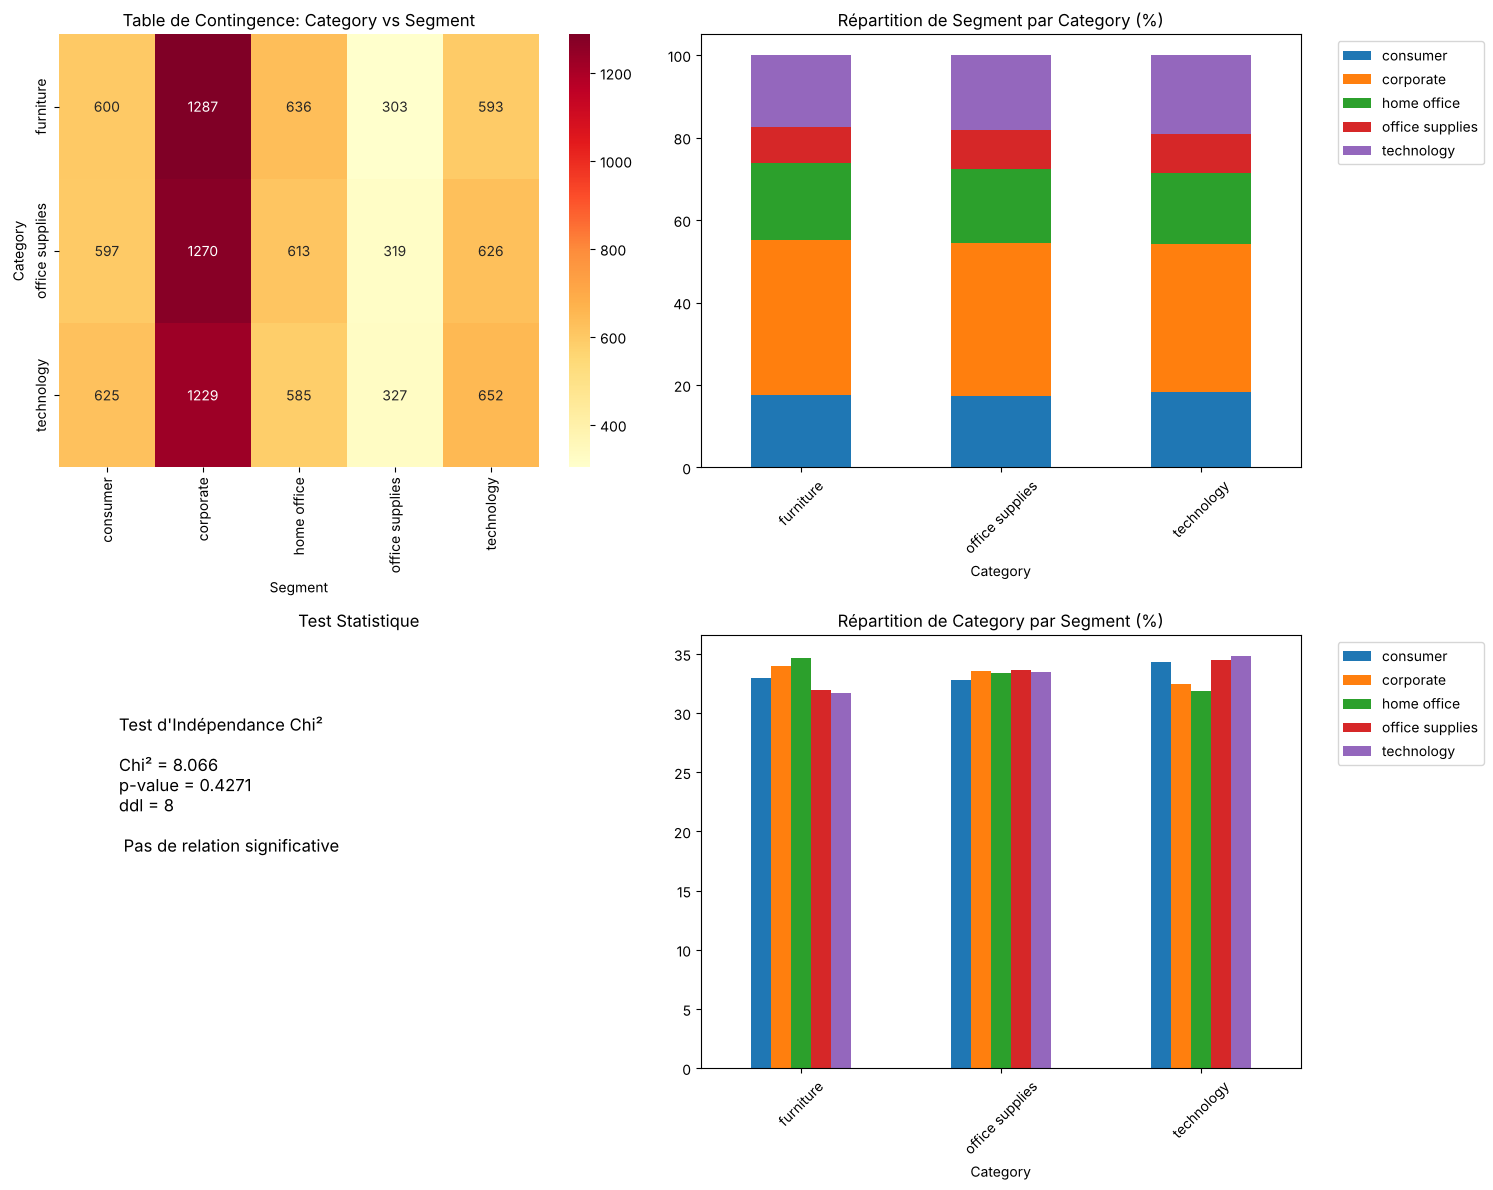

In [24]:
chi2, p_value = categorical_vs_categorical(df, 'Category', 'Segment')

In [25]:
def multivariate_analysis(df, numerical_cols, categorical_cols):
    """Analyse multivariée avancée"""

    # Pairplot avec hue si peu de catégories
    if len(categorical_cols) > 0:
        hue_col = categorical_cols[0] if df[categorical_cols[0]].nunique() <= 5 else None
        if hue_col:
            sns.pairplot(df[numerical_cols[:4] + [hue_col]], hue=hue_col, diag_kind='hist')
            plt.suptitle('Pairplot Multivarié', y=1.02)
            plt.show()

    # Parallel coordinates pour les catégories
    if len(numerical_cols) >= 3 and len(categorical_cols) > 0:
        from pandas.plotting import parallel_coordinates

        #préparer les données
        parallel_data = df[numerical_cols[:3] + [categorical_cols[0]]].copy()
        parallel_data = parallel_data.groupby(categorical_cols[0]).mean().reset_index()

        plt.figure(figsize=(12, 6))
        parallel_coordinates(parallel_data, categorical_cols[0])
        plt.title('Coordonnées Parallèles - Profils par Catégorie')
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

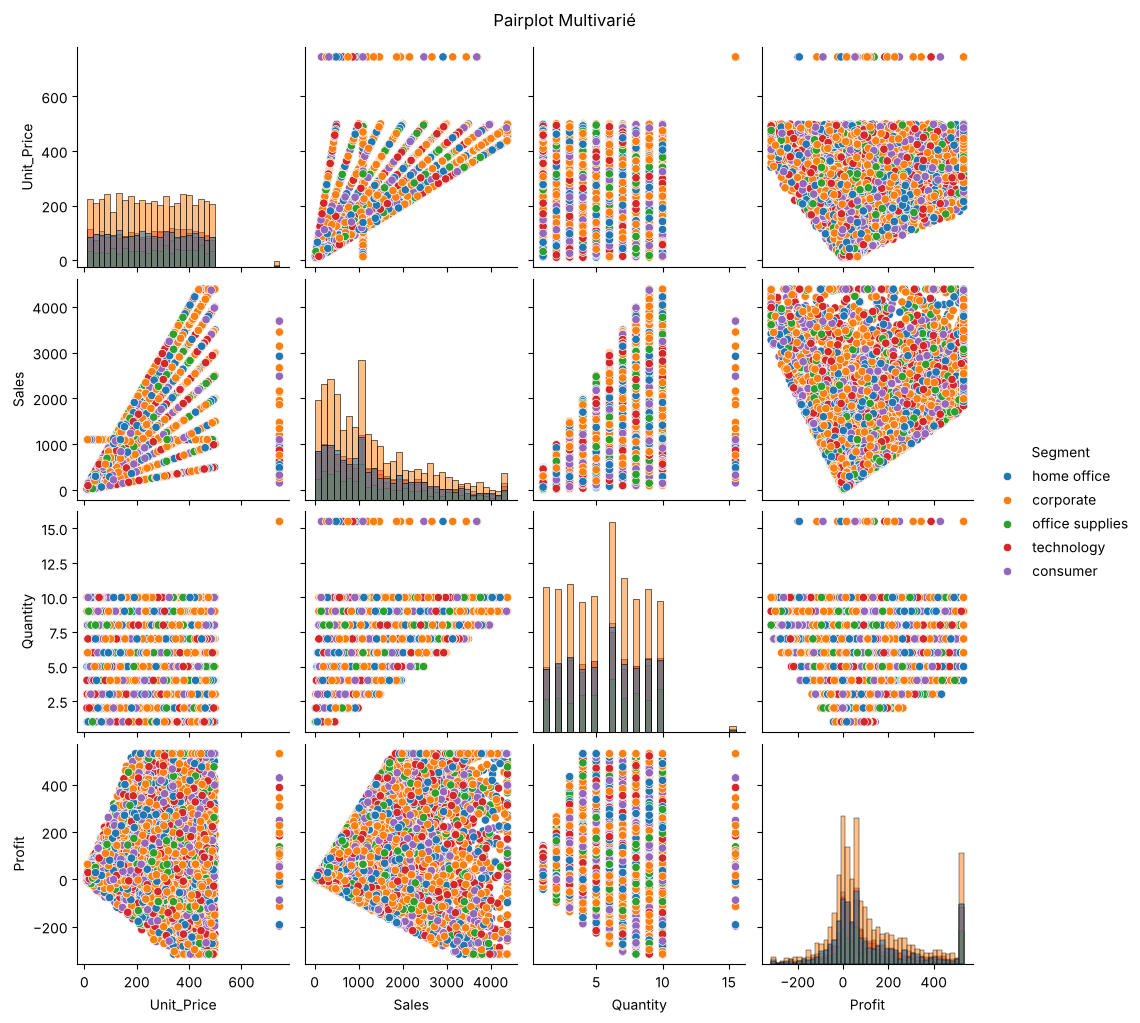

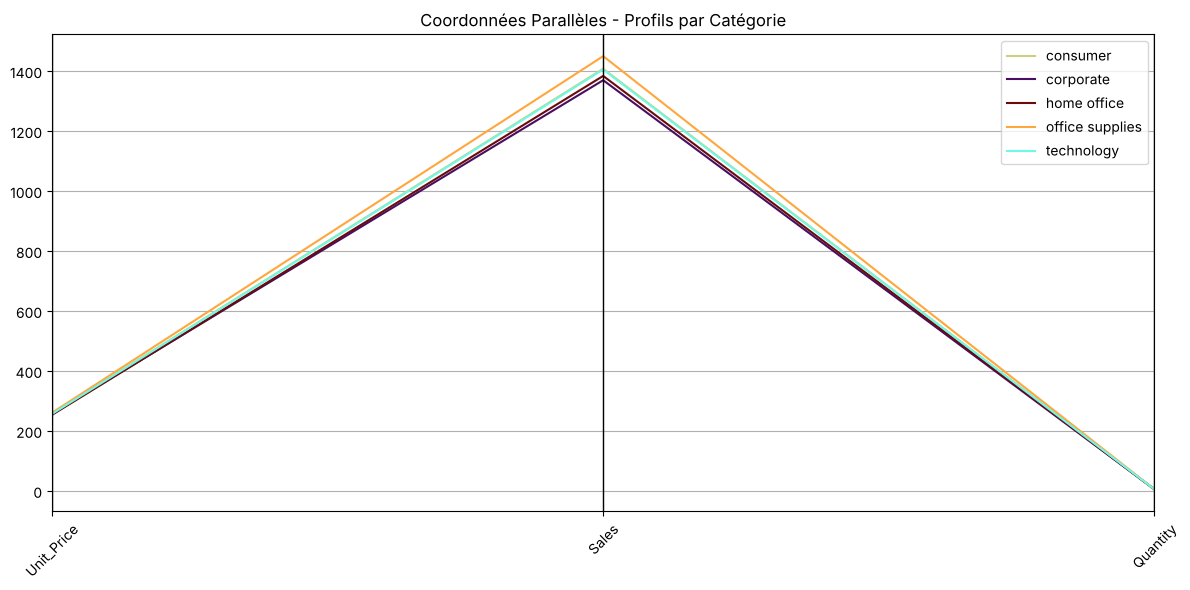

In [26]:
multivariate_analysis(df, numerical_cols, categorical_cols)

# Step 3 : Séries temporelles et tendance

In [27]:
def temporal_analysis(df, date_col, value_col):
    """Analyse temporelle des données"""

    # S'assurer que la colonne date est au bon format
    df[date_col] = pd.to_datetime(df[date_col])
    df_temp = df.set_index(date_col).sort_index()

    # Agrégations temporelles
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))

    # Tendances mensuelles
    monthly = df_temp[value_col].resample('ME').sum()
    axes[0,0].plot(monthly.index, monthly.values, marker='o')
    axes[0,0].set_title(f'Tendance Mensuelle de {value_col}')
    axes[0,0].tick_params(axis='x', rotation=45)

    # Tendances hebdomadaires
    df_temp['dayofweek'] = df_temp.index.dayofweek
    weekly_pattern = df_temp.groupby('dayofweek')[value_col].mean()
    days = ['Lun', 'Mar', 'Mer', 'Jeu', 'Ven', 'Sam', 'Dim']
    axes[0,1].bar(range(7), weekly_pattern.values)
    axes[0,1].set_xticks(range(7))
    axes[0,1].set_xticklabels(days)
    axes[0,1].set_title(f'Pattern Hebdomadaire de {value_col}')

    # Saisonnalité mensuelle
    df_temp['month'] = df_temp.index.month
    monthly_pattern = df_temp.groupby('month')[value_col].mean()
    axes[1,0].bar(range(1, 13), monthly_pattern.values)
    axes[1,0].set_title(f'Saisonnalité Mensuelle de {value_col}')
    axes[1,0].set_xlabel('Mois')

    # Rolling average
    weekly_rolling = df_temp[value_col].resample('W').sum().rolling(window=4).mean()
    axes[1,1].plot(weekly_rolling.index, weekly_rolling.values)
    axes[1,1].set_title(f'Moyenne Mobile (4 semaines) de {value_col}')
    axes[1,1].tick_params(axis='x', rotation=45)

    plt.tight_layout()
    plt.show()

    # Stats temporelles
    print("=== STATISTIQUES TEMPORELLES ===")
    print(f"Période couverte: {df_temp.index.min()} to {df_temp.index.max()}")
    print(f"Durée totale: {(df_temp.index.max() - df_temp.index.min()).days} jours")
    print(f"Growth rate: {((monthly.iloc[-1] - monthly.iloc[0]) / monthly.iloc[0]) * 100:.1f}%")


In [28]:
df

,Order_ID,Order_Date,Ship_Date,Customer_Name,Segment,Product_ID,Product_Name,Category,Sub-Category,Unit_Price,Sales,Quantity,Profit,Store,Country_of_store,Weekly_sales
0,ORD-3872,2023-11-27,2023-11-29,Pro Services,home office,PROD-6008,Generic Product,furniture,white boards,409.33,1227.99,3.0,-70.06,n&j store,switzerland,1258.68
1,ORD-1884,2024-03-09,2024-03-10,Corporate World,corporate,PROD-2774,Generic Product,technology,power banks,231.61,231.61,1.0,13.65,b&d store,belgium,219.55
2,ORD-2565,2024-06-16,2024-06-24,Enterprise Group,corporate,PROD-2069,Generic Product,furniture,desks,493.60,3455.20,7.0,-156.79,a&c store,france,3992.36
3,ORD-3589,2023-06-30,2023-07-01,SafeSpace,home office,PROD-2518,Generic Product,technology,power banks,100.94,706.58,7.0,52.28,n&j store,switzerland,607.35
4,ORD-6146,2023-06-09,2023-06-14,OfficePlus,office supplies,PROD-1391,Generic Product,technology,chargers,47.09,282.54,6.0,-1.16,a&c store,france,293.56
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10315,ORD-6893,2024-11-18,2024-11-24,Innovate Ltd,corporate,PROD-7351,Desktop Pro,technology,computers,238.01,1428.06,6.0,225.41,a&c store,france,1459.40
10316,ORD-6260,2024-04-26,2024-05-04,Innovate Ltd,corporate,PROD-5241,Generic Product,furniture,furnishings,80.82,565.74,7.0,109.74,n&j store,switzerland,643.62
10317,ORD-7692,2024-12-23,2024-12-30,Pro Services,home office,PROD-6627,Generic Product,furniture,tables,65.40,65.40,1.0,16.54,a&b store,france,73.11
10318,ORD-9512,2023-04-23,2023-05-03,OfficePlus,office supplies,PROD-3860,Generic Product,technology,power banks,316.16,1099.98,6.0,63.60,b&d store,belgium,1093.23


In [29]:
df['Country_of_store']

0        switzerland
1            belgium
2             france
3        switzerland
4             france
            ...     
10315         france
10316    switzerland
10317         france
10318        belgium
10319         france
Name: Country_of_store, Length: 10262, dtype: object

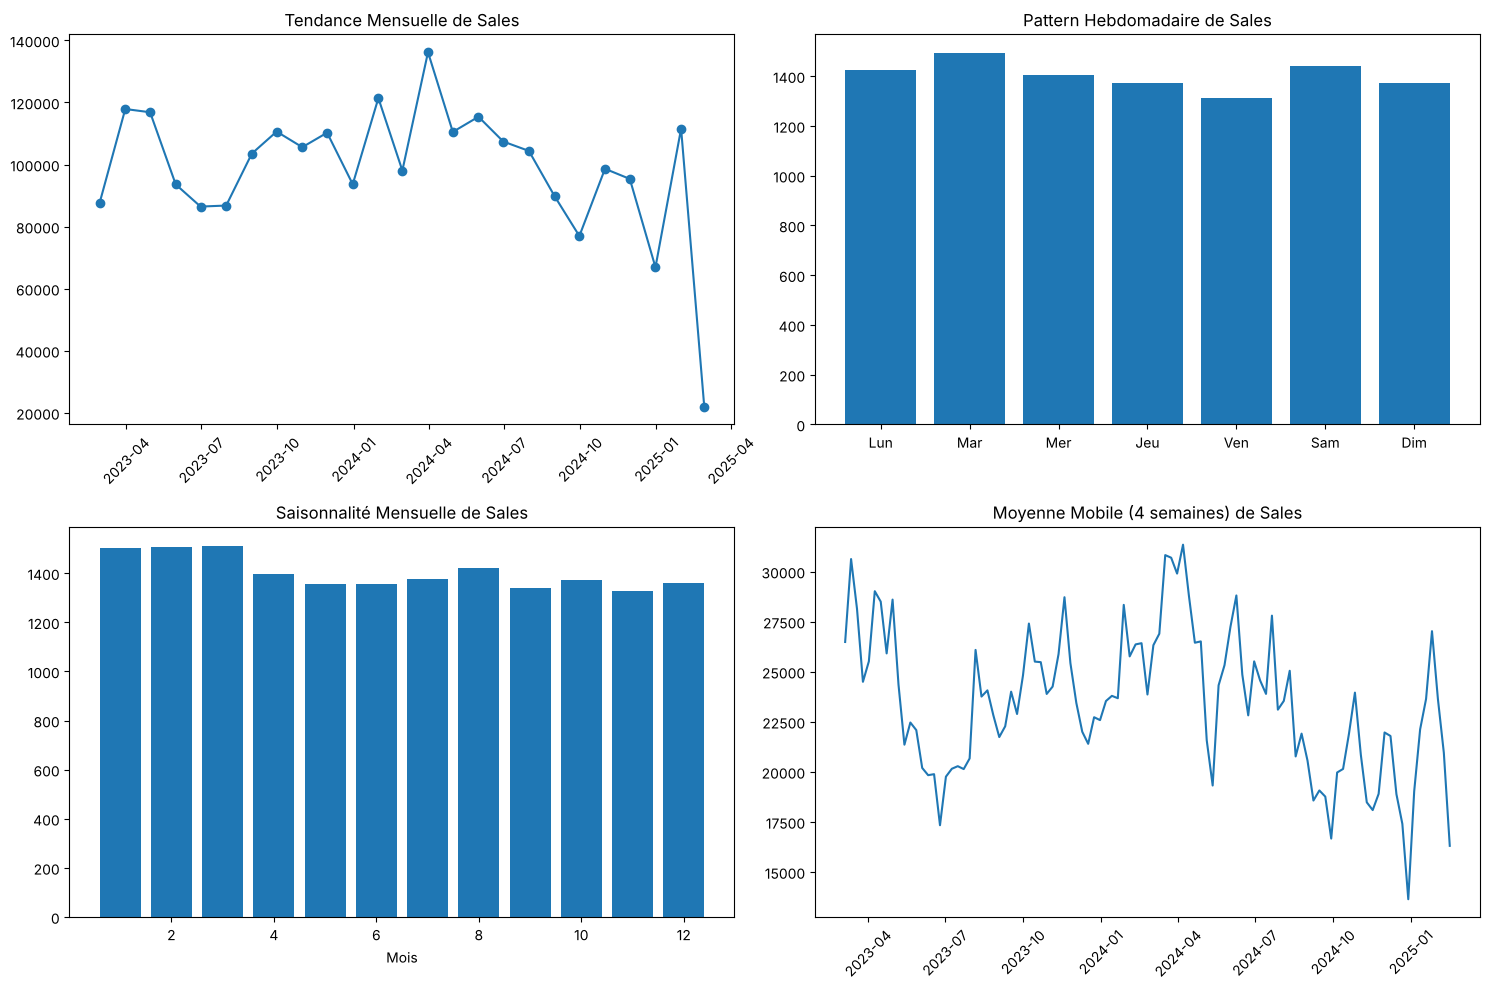

=== STATISTIQUES TEMPORELLES ===
Période couverte: 2023-02-12 00:00:00 to 2025-02-10 00:00:00
Durée totale: 729 jours
Growth rate: -74.9%


In [30]:
df_aetb_store = df[df['Store']== 'n&j store']

# ventes par rapport à date de commande
if 'Order_Date' in df_aetb_store.columns:
    temporal_analysis(df_aetb_store, 'Order_Date', 'Sales')

In [31]:
df_country = df[df['Country_of_store']== 'france']
df_country

,Order_ID,Order_Date,Ship_Date,Customer_Name,Segment,Product_ID,Product_Name,Category,Sub-Category,Unit_Price,Sales,Quantity,Profit,Store,Country_of_store,Weekly_sales
2,ORD-2565,2024-06-16,2024-06-24,Enterprise Group,corporate,PROD-2069,Generic Product,furniture,desks,493.60,3455.20,7.0,-156.7900,a&c store,france,3992.36
4,ORD-6146,2023-06-09,2023-06-14,OfficePlus,office supplies,PROD-1391,Generic Product,technology,chargers,47.09,282.54,6.0,-1.1600,a&c store,france,293.56
5,ORD-4939,2024-08-24,2024-08-30,Enterprise Group,corporate,PROD-5772,Generic Product,furniture,white boards,48.57,485.70,10.0,-2.6100,a&b store,france,405.49
6,ORD-5877,2024-04-02,2024-04-11,TechData,technology,PROD-4526,Wireless Phone,technology,phones,440.30,3522.40,8.0,447.5000,a&c store,france,3283.44
7,ORD-8155,2024-06-04,2024-06-08,OfficePlus,office supplies,PROD-5387,Generic Product,furniture,bookcases,361.35,2890.80,8.0,531.5425,a&b store,france,3254.72
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10311,ORD-3852,2024-10-19,2024-10-28,Innovate Ltd,corporate,PROD-1259,Generic Product,technology,ink for copiers,239.83,479.66,2.0,-40.2200,a&c store,france,499.85
10312,ORD-4531,2023-08-01,2023-08-11,TechData,technology,PROD-7374,Laptop Elite,technology,computers,169.64,169.64,1.0,-6.4800,a&c store,france,167.24
10315,ORD-6893,2024-11-18,2024-11-24,Innovate Ltd,corporate,PROD-7351,Desktop Pro,technology,computers,238.01,1428.06,6.0,225.4100,a&c store,france,1459.40
10317,ORD-7692,2024-12-23,2024-12-30,Pro Services,home office,PROD-6627,Generic Product,furniture,tables,65.40,65.40,1.0,16.5400,a&b store,france,73.11


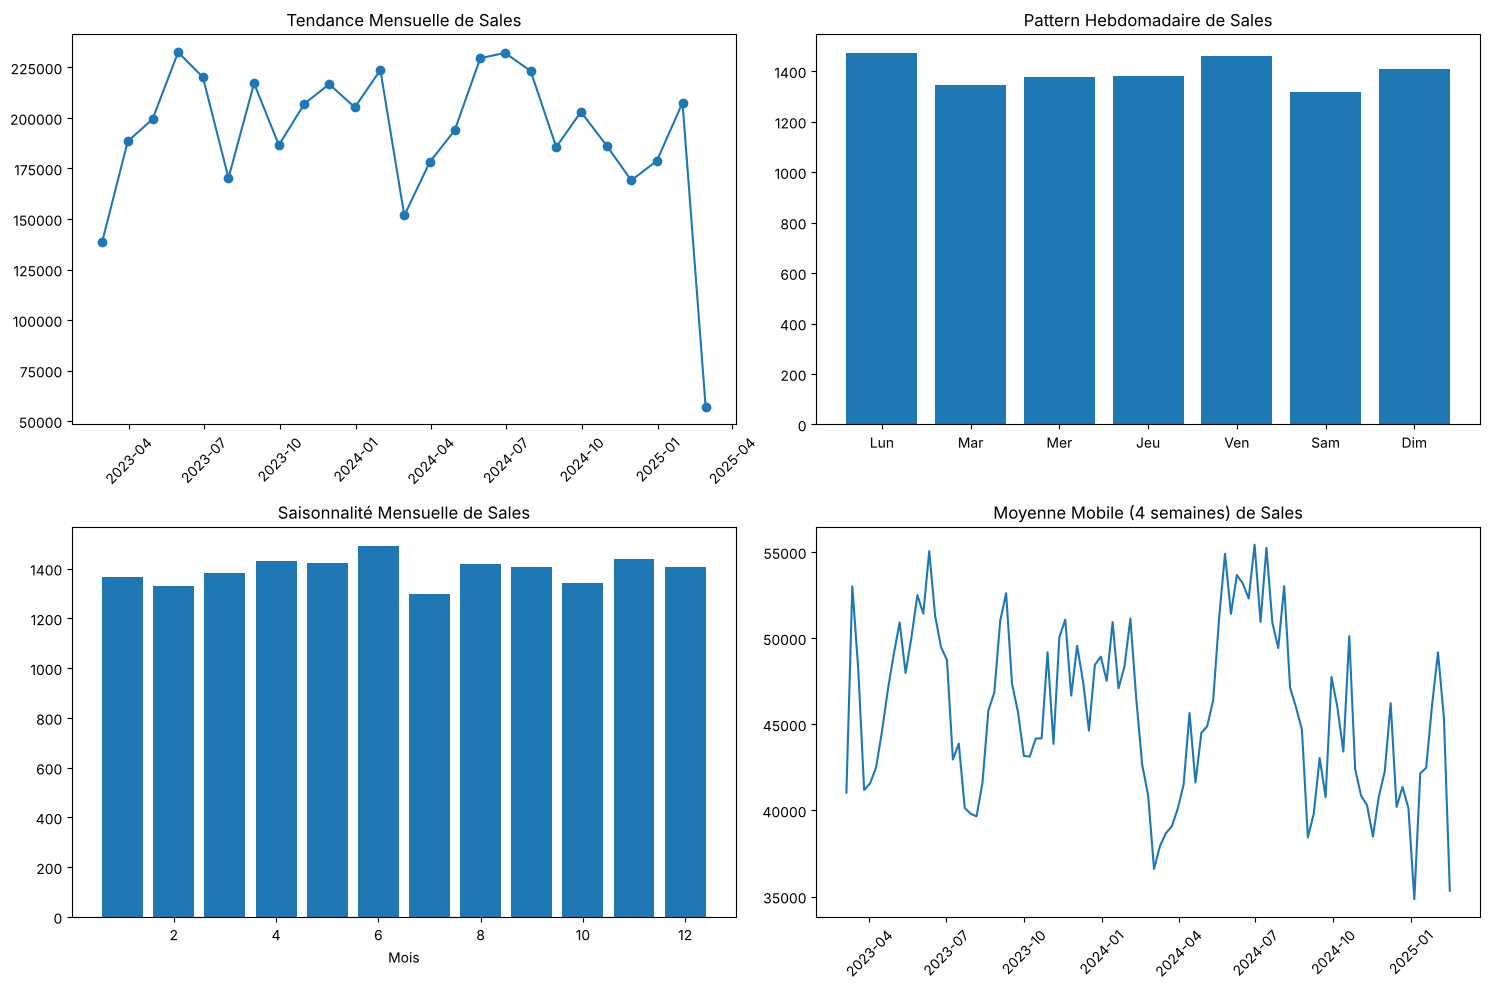

=== STATISTIQUES TEMPORELLES ===
Période couverte: 2023-02-12 00:00:00 to 2025-02-10 00:00:00
Durée totale: 729 jours
Growth rate: -58.9%


In [32]:

# ventes par rapport à date de commande
if 'Order_Date' in df_country.columns:
    temporal_analysis(df_country, 'Order_Date', 'Sales')

In [33]:
# Supposons que ton DataFrame s'appelle df_clean
df.to_csv("base_donnees_nettoyee.csv", index=False)


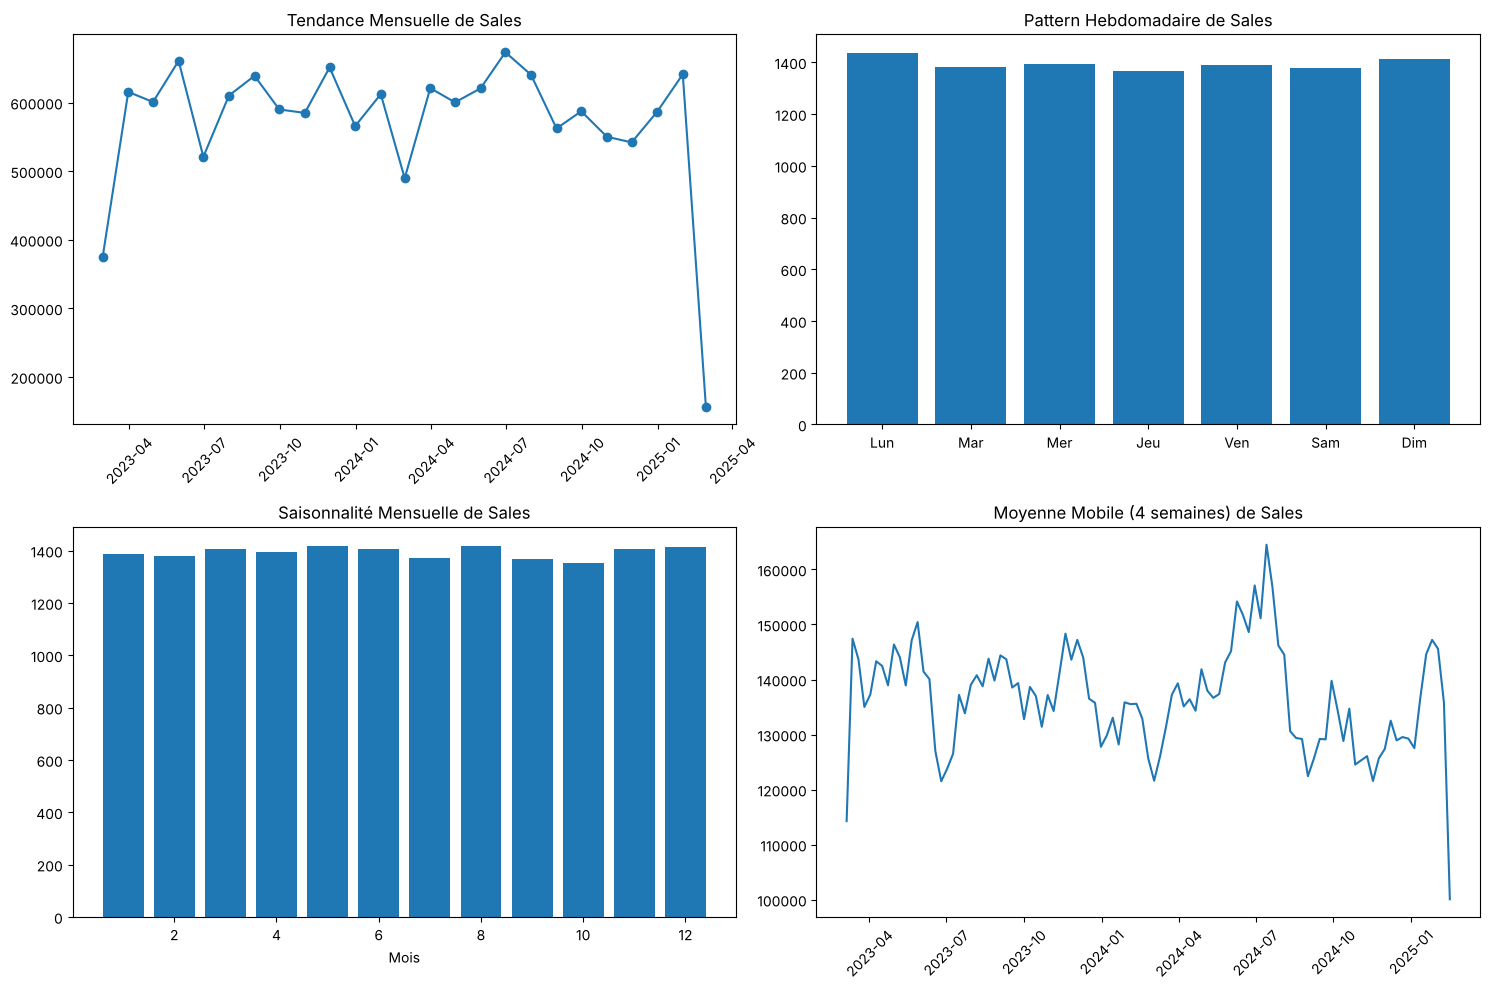

=== STATISTIQUES TEMPORELLES ===
Période couverte: 2023-02-12 00:00:00 to 2025-02-10 00:00:00
Durée totale: 729 jours
Growth rate: -58.3%


In [34]:
# ventes par rapport à date de commande
if 'Order_Date' in df.columns:
    temporal_analysis(df, 'Order_Date', 'Sales')

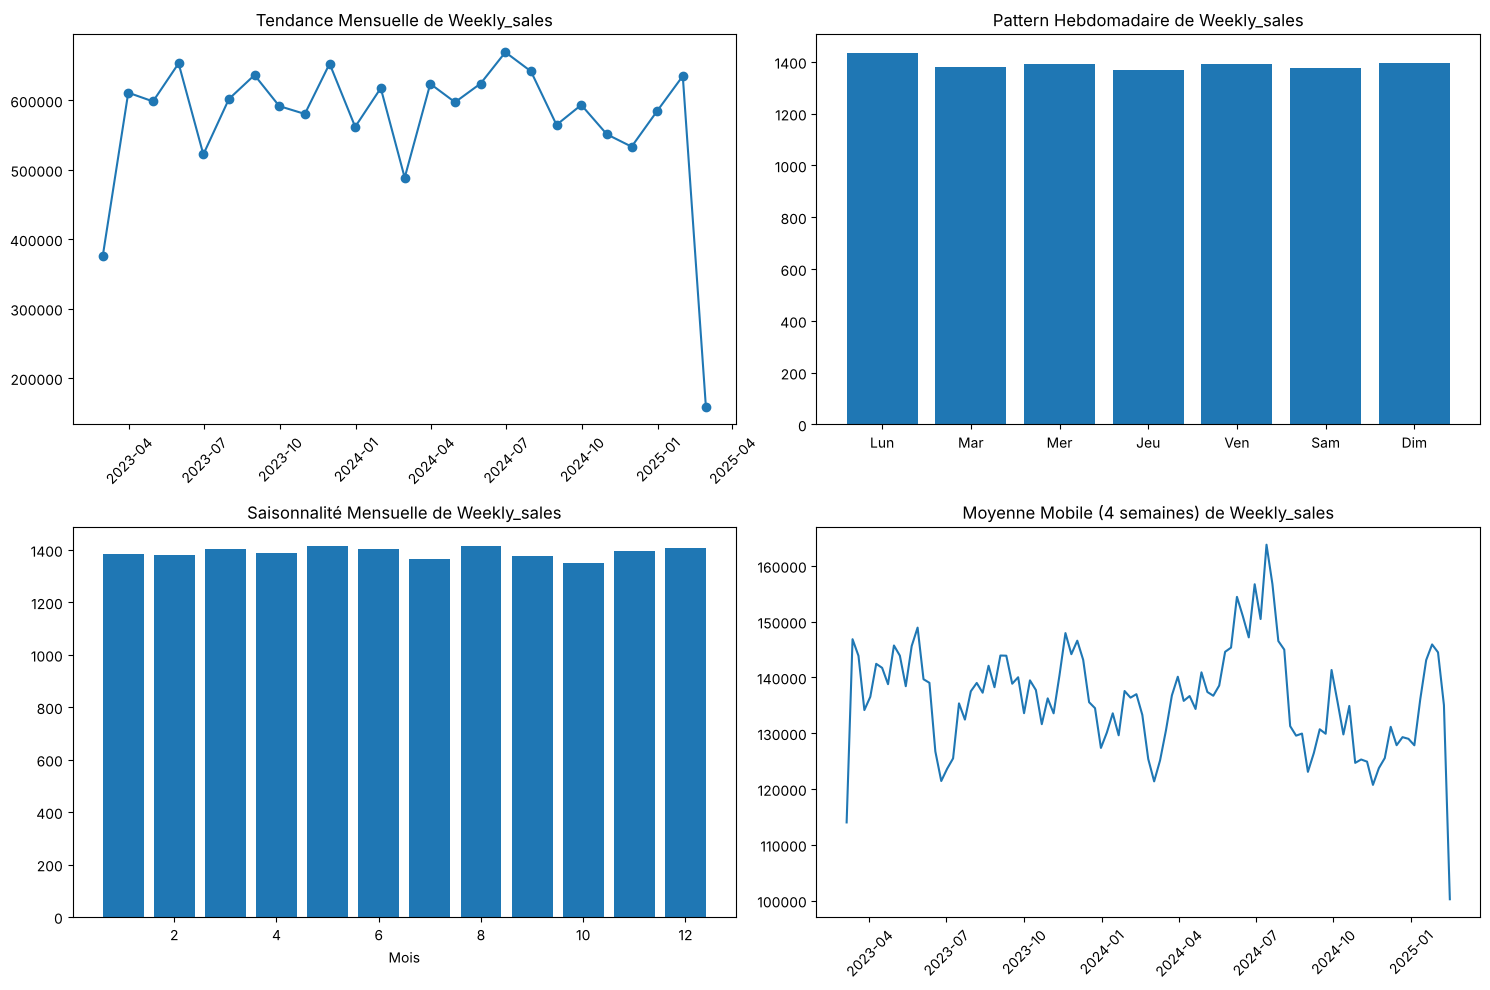

=== STATISTIQUES TEMPORELLES ===
Période couverte: 2023-02-12 00:00:00 to 2025-02-10 00:00:00
Durée totale: 729 jours
Growth rate: -57.7%


In [35]:
# ventes par semaine par rapport à date de livraison 
if 'Order_Date' in df.columns:
    temporal_analysis(df, 'Order_Date', 'Weekly_sales')

In [36]:
def initial_assessment(df):
    """évaluation initiale complète du dataset"""

    print("=== STATISTIQUES DESCRIPTIVES ===")
    print(df.describe(include='all'))

    print("\n=== VALEURS MANQUANTES ===")
    missing_data = df.isnull().sum()
    missing_percent = (missing_data / len(df)) * 100
    missing_df = pd.DataFrame({
        'Valeurs_manquantes': missing_data,
        'Pourcentage': missing_percent
    })
    print(missing_df[missing_df['Valeurs_manquantes'] > 0])

    print("\n=== DOUBLONS ===")
    print(f"Doublons exacts: {df.duplicated().sum()}")

    print("\n=== TYPES DE DONNEES ===")
    print(df.dtypes.value_counts())

    return missing_df

missing_summary = initial_assessment(df)

=== STATISTIQUES DESCRIPTIVES ===
        Order_ID                  Order_Date                   Ship_Date  \
count      10262                       10262                       10262   
unique     10261                         NaN                         NaN   
top     ORD-1968                         NaN                         NaN   
freq           2                         NaN                         NaN   
mean         NaN  2024-02-10 21:09:05.156889  2024-02-16 08:09:01.648801   
min          NaN         2023-02-12 00:00:00         2023-02-13 00:00:00   
25%          NaN         2023-08-12 00:00:00         2023-08-18 00:00:00   
50%          NaN         2024-02-13 00:00:00         2024-02-19 00:00:00   
75%          NaN         2024-08-08 00:00:00         2024-08-13 00:00:00   
max          NaN         2025-02-10 00:00:00         2025-02-19 00:00:00   
std          NaN                         NaN                         NaN   

           Customer_Name    Segment Product_ID     Pr

In [37]:
df


,Order_ID,Order_Date,Ship_Date,Customer_Name,Segment,Product_ID,Product_Name,Category,Sub-Category,Unit_Price,Sales,Quantity,Profit,Store,Country_of_store,Weekly_sales
0,ORD-3872,2023-11-27,2023-11-29,Pro Services,home office,PROD-6008,Generic Product,furniture,white boards,409.33,1227.99,3.0,-70.06,n&j store,switzerland,1258.68
1,ORD-1884,2024-03-09,2024-03-10,Corporate World,corporate,PROD-2774,Generic Product,technology,power banks,231.61,231.61,1.0,13.65,b&d store,belgium,219.55
2,ORD-2565,2024-06-16,2024-06-24,Enterprise Group,corporate,PROD-2069,Generic Product,furniture,desks,493.60,3455.20,7.0,-156.79,a&c store,france,3992.36
3,ORD-3589,2023-06-30,2023-07-01,SafeSpace,home office,PROD-2518,Generic Product,technology,power banks,100.94,706.58,7.0,52.28,n&j store,switzerland,607.35
4,ORD-6146,2023-06-09,2023-06-14,OfficePlus,office supplies,PROD-1391,Generic Product,technology,chargers,47.09,282.54,6.0,-1.16,a&c store,france,293.56
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10315,ORD-6893,2024-11-18,2024-11-24,Innovate Ltd,corporate,PROD-7351,Desktop Pro,technology,computers,238.01,1428.06,6.0,225.41,a&c store,france,1459.40
10316,ORD-6260,2024-04-26,2024-05-04,Innovate Ltd,corporate,PROD-5241,Generic Product,furniture,furnishings,80.82,565.74,7.0,109.74,n&j store,switzerland,643.62
10317,ORD-7692,2024-12-23,2024-12-30,Pro Services,home office,PROD-6627,Generic Product,furniture,tables,65.40,65.40,1.0,16.54,a&b store,france,73.11
10318,ORD-9512,2023-04-23,2023-05-03,OfficePlus,office supplies,PROD-3860,Generic Product,technology,power banks,316.16,1099.98,6.0,63.60,b&d store,belgium,1093.23


kpi


In [38]:
# chiffre d affiare 
ca = df['Sales'].sum()
ca
# un bon chiffre d affaire 

np.float64(14300557.32)

In [39]:
# chiffre d affaire par mois
ca_mois = df['Weekly_sales'].groupby(df['Country_of_store']).sum()
ca_mois
# la france a le meilleur chiffre d affaire mensuelle c est un pays ou il faudra plus se tourner pour augmenter aussi la rentabilite. Les autres pays sont a peut près 
# au meme niveau en terme de ca 

Country_of_store
belgium        2.320616e+06
france         4.802237e+06
portugal       2.362622e+06
spain          2.328029e+06
switzerland    2.459702e+06
Name: Weekly_sales, dtype: float64

In [40]:
# chiffre d affaire par  nom de produit
ca_produit = df['Sales'].groupby(df['Product_Name']).sum()
ca_produit

# generic produit rapporte le plus de ca il est le plus rentable

Product_Name
A4 Paper Premium      155288.97
Adapter               145722.52
Binder Pro            127018.82
Binder X100           166370.60
Business Phone        152661.12
Charger               149405.65
Coffee Table          167773.32
Color Paper           136721.27
Color Pencils         147329.76
Conference Table      222844.62
Desk Pro              175902.02
Desktop Pro           139644.56
Drawing Set           117149.00
Ergonomic Chair       174776.10
Executive Chair       206451.09
Flex Binder           169162.13
Generic Product     10607585.55
Laptop Elite          125996.17
Recycled Paper        151342.35
SmartPhone Pro        114710.93
Standard Chair        153162.76
Tablet Air            131658.37
USB Cable             136310.09
Watercolor            152004.22
Wireless Phone        173565.33
Name: Sales, dtype: float64

In [41]:
# chiffrre d affaire par category de produit
ca_cat = df['Sales'].groupby(df['Category']).sum()
ca_cat
# le ciffre d affaires au niveau des categories est a peut près le meme resultat donc une constante. chaque categorie rapporte au chiffre affaire normal

Category
furniture          4796565.23
office supplies    4794682.48
technology         4709309.61
Name: Sales, dtype: float64

In [42]:
# somme des ventes par nom de produit
vents_produit = df['Sales'].groupby(df['Product_Name']).sum()
vents_produit.nlargest(10)

#vents_produit
# cest le tp 10 des produit les plus vendus avec generic product qui est en tete un produit sur lequel on devrait plus investir car il est rentable

Product_Name
Generic Product     10607585.55
Conference Table      222844.62
Executive Chair       206451.09
Desk Pro              175902.02
Ergonomic Chair       174776.10
Wireless Phone        173565.33
Flex Binder           169162.13
Coffee Table          167773.32
Binder X100           166370.60
A4 Paper Premium      155288.97
Name: Sales, dtype: float64

In [43]:
# somme des vents par categories
vents_cat = df['Sales'].groupby(df['Category']).sum()
vents_cat
#ici on voit  que toutes les categories rapportent et sont bien vendu ils sont a peu près au meme point de vente en terme de chiffre

Category
furniture          4796565.23
office supplies    4794682.48
technology         4709309.61
Name: Sales, dtype: float64

In [44]:
# somme des ventes par segment
vents_seg = df['Sales'].groupby(df['Segment']).sum()
vents_seg
# le segment corporate  est le plus vendu ici , c est le client qui genère le plus d argent

Segment
consumer           2566594.12
corporate          5187883.34
home office        2539257.23
office supplies    1376579.74
technology         2630242.89
Name: Sales, dtype: float64

In [45]:
#profit par segemnt
profit_seg = df['Profit'].groupby(df['Segment']).sum()
profit_seg
# le segment corporate a le plus de profit donc rapport beaucoup 

Segment
consumer           226060.9400
corporate          442149.7300
home office        218179.0600
office supplies    122935.3050
technology         231442.5125
Name: Profit, dtype: float64

In [46]:
# profit par produit 
profit_produit = df['Profit'].groupby(df['Product_Name']).sum()
profit_produit
profit_produit.nlargest(10)

# le generic product rapporte plus de profit 

Product_Name
Generic Product     940324.1800
Conference Table     19021.5625
A4 Paper Premium     15047.0650
Flex Binder          14739.8200
Standard Chair       14739.3925
Executive Chair      14572.0125
Ergonomic Chair      14473.3375
Coffee Table         14392.0425
Business Phone       13081.4525
Binder X100          12833.2975
Name: Profit, dtype: float64

In [47]:
# profit par  cat de produit 
profit_cat_produit = df['Profit'].groupby(df['Category']).sum()
profit_cat_produit

# LA  on voit que le office suplies a le plus de produit une bonne rentabilite avec sa 

Category
furniture          412853.4300
office supplies    434571.5900
technology         393342.5275
Name: Profit, dtype: float64

In [48]:
# la marge
profit =  df['Profit'].sum()
marge = profit / ca
marge

np.float64(0.08676357988962628)

In [49]:
df['marge']= df['Profit'].sum()/ ca

In [50]:
marge_produit = df.groupby(df['Category'])['marge'].sum()
marge_produit

Category
furniture          296.644680
office supplies    297.165261
technology         296.557916
Name: marge, dtype: float64

In [51]:
# taux de croissance 
p_D = df['Profit'].iloc[0]
p_F = df['Profit'].iloc[-1]

taux_de_croissance = ((p_D - p_F) / p_D ) * 100
taux_de_croissance

np.float64(140.7507850413931)

In [52]:
df['taux_de_croissance'] = ((p_D - p_F) / p_D ) * 100

In [53]:
# taux de croissance par produit
TDC_produit = df.groupby(df['Product_Name'])['taux_de_croissance'].sum()
TDC_produit

Product_Name
A4 Paper Premium    1.562334e+04
Adapter             1.548259e+04
Binder Pro          1.379358e+04
Binder X100         1.576409e+04
Business Phone      1.477883e+04
Charger             1.520108e+04
Coffee Table        1.618634e+04
Color Paper         1.421583e+04
Color Pencils       1.534184e+04
Conference Table    2.237937e+04
Desk Pro            1.871985e+04
Desktop Pro         1.393433e+04
Drawing Set         1.379358e+04
Ergonomic Chair     1.759385e+04
Executive Chair     1.843835e+04
Flex Binder         1.604559e+04
Generic Product     1.070269e+06
Laptop Elite        1.365283e+04
Recycled Paper      1.379358e+04
SmartPhone Pro      1.224532e+04
Standard Chair      1.632709e+04
Tablet Air          1.308982e+04
USB Cable           1.506033e+04
Watercolor          1.632709e+04
Wireless Phone      1.632709e+04
Name: taux_de_croissance, dtype: float64

In [54]:
# taux de croissance par produit
TDC_produit = df.groupby(df['Category'])['taux_de_croissance'].sum()
TDC_produit

Category
furniture          481226.934057
office supplies    482071.438767
technology         481086.183271
Name: taux_de_croissance, dtype: float64

In [55]:
df

,Order_ID,Order_Date,Ship_Date,Customer_Name,Segment,Product_ID,Product_Name,Category,Sub-Category,Unit_Price,Sales,Quantity,Profit,Store,Country_of_store,Weekly_sales,marge,taux_de_croissance
0,ORD-3872,2023-11-27,2023-11-29,Pro Services,home office,PROD-6008,Generic Product,furniture,white boards,409.33,1227.99,3.0,-70.06,n&j store,switzerland,1258.68,0.086764,140.750785
1,ORD-1884,2024-03-09,2024-03-10,Corporate World,corporate,PROD-2774,Generic Product,technology,power banks,231.61,231.61,1.0,13.65,b&d store,belgium,219.55,0.086764,140.750785
2,ORD-2565,2024-06-16,2024-06-24,Enterprise Group,corporate,PROD-2069,Generic Product,furniture,desks,493.60,3455.20,7.0,-156.79,a&c store,france,3992.36,0.086764,140.750785
3,ORD-3589,2023-06-30,2023-07-01,SafeSpace,home office,PROD-2518,Generic Product,technology,power banks,100.94,706.58,7.0,52.28,n&j store,switzerland,607.35,0.086764,140.750785
4,ORD-6146,2023-06-09,2023-06-14,OfficePlus,office supplies,PROD-1391,Generic Product,technology,chargers,47.09,282.54,6.0,-1.16,a&c store,france,293.56,0.086764,140.750785
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10315,ORD-6893,2024-11-18,2024-11-24,Innovate Ltd,corporate,PROD-7351,Desktop Pro,technology,computers,238.01,1428.06,6.0,225.41,a&c store,france,1459.40,0.086764,140.750785
10316,ORD-6260,2024-04-26,2024-05-04,Innovate Ltd,corporate,PROD-5241,Generic Product,furniture,furnishings,80.82,565.74,7.0,109.74,n&j store,switzerland,643.62,0.086764,140.750785
10317,ORD-7692,2024-12-23,2024-12-30,Pro Services,home office,PROD-6627,Generic Product,furniture,tables,65.40,65.40,1.0,16.54,a&b store,france,73.11,0.086764,140.750785
10318,ORD-9512,2023-04-23,2023-05-03,OfficePlus,office supplies,PROD-3860,Generic Product,technology,power banks,316.16,1099.98,6.0,63.60,b&d store,belgium,1093.23,0.086764,140.750785


In [56]:
df['Order_Date'] = pd.to_datetime(df['Order_Date'])
most_recent_date = df['Order_Date'].max()
print(f"la date de vente la plus récente est: {most_recent_date}")

la date de vente la plus récente est: 2025-02-10 00:00:00


In [57]:
# date de référence = lendemain de la dernière commande du jeu de données (résultat reproductible)
most_recent_date = df['Order_Date'].max() + pd.Timedelta(days=1)

df_rfm = df.groupby('Customer_Name').agg(
    Recency=('Order_Date', lambda date: (most_recent_date - date.max()).days),
    Frequency=('Customer_Name', 'count'),
    Monetary=('Sales', 'sum')
).reset_index()

display(df_rfm.head())

,Customer_Name,Recency,Frequency,Monetary
0,Astronomer,2,921,1270968.83
1,Business Solutions,1,911,1192840.34
2,Corporate World,1,940,1282368.01
3,Enterprise Group,2,970,1390303.92
4,Global Partners,1,901,1295625.29


In [58]:
df_rfm['R_score'] = pd.qcut(df_rfm['Recency'], 5, duplicates="drop")

In [59]:

# Determiner le nombre des bins unique après avoir enlever les doublons pour frequence et monetisation
freq_bins = pd.qcut(df_rfm['Frequency'], 5, duplicates='drop', retbins=True)[1]
monetary_bins = pd.qcut(df_rfm['Monetary'], 5, duplicates='drop', retbins=True)[1]

# ajuster le nombre des labeks en se basant sur le nombre des bins
freq_labels = [i for i in range(1, len(freq_bins))]
monetary_labels = [i for i in range(1, len(monetary_bins))]

df_rfm['F_score'] = pd.qcut(df_rfm['Frequency'], q=5, labels=freq_labels, duplicates='drop')
df_rfm['M_score'] = pd.qcut(df_rfm['Monetary'], q=5, labels=monetary_labels, duplicates='drop')


df_rfm['RFM_Segment'] = df_rfm['R_score'].astype(str) + df_rfm['F_score'].astype(str) + df_rfm['M_score'].astype(str)

display(df_rfm.head())

,Customer_Name,Recency,Frequency,Monetary,R_score,F_score,M_score,RFM_Segment
0,Astronomer,2,921,1270968.83,"(0.999, 2.0]",2,1,"(0.999, 2.0]21"
1,Business Solutions,1,911,1192840.34,"(0.999, 2.0]",2,1,"(0.999, 2.0]21"
2,Corporate World,1,940,1282368.01,"(0.999, 2.0]",3,2,"(0.999, 2.0]32"
3,Enterprise Group,2,970,1390303.92,"(0.999, 2.0]",5,5,"(0.999, 2.0]55"
4,Global Partners,1,901,1295625.29,"(0.999, 2.0]",1,3,"(0.999, 2.0]13"


In [60]:
# Define RFM levels based on scores
def rfm_level(df):
    if df['RFM_Segment'] == '555':
        return 'Champions' #  VERY High Recency, High frequency, High Monetary
    elif df['R_score'] >= 5 and df['F_score'] >= 5:
        return 'Loyal' # VERY High Recency, High frequency
    elif df['R_score'] >= 4 and df['F_score'] >= 4:
        return 'Loyal' # High Recency, High frequency
    elif df['R_score'] >= 3 and df['F_score'] >= 3:
        return 'Potential Loyal' # Medium Recency, Medium Frequency
    elif df['R_score'] >= 5 and df['F_score'] >= 5:
        return 'Loyal' # VERY HIG Recency, HIG frequency
    elif df['R_score'] >= 4 and df['M_score'] >= 4:
        return 'Big Spenders' # High Recency, High Monetary
    elif df['R_score'] >= 3 and df['M_score'] >= 3:
         return 'Potential Big Spenders' # Medium Recency, Medium Monetary
    elif df['R_score'] >= 5 and df['F_score'] >= 5:
        return 'Loyal' # VERY  High Recency, High frequency
    elif df['F_score'] >= 4 and df['M_score'] >= 4:
        return 'Most Engaged' # High frequency, High Monetary
    elif df['F_score'] >= 3 and df['M_score'] >= 3:
        return 'Potential Most Engaged' # Medium frequency, Medium Monetary
    elif df['R_score'] <= 2 and df['F_score'] <= 2 and df['M_score'] <= 2:
        return 'Lost' # Low Recency, Low frequency, Low Monetary
    else:
        return 'Others' # All other combinations

# Applique rla fonction à la nouvelle col 'RFM_Level'
df_rfm['F_Score'] = pd.qcut(df_rfm['Frequency'].rank(method='first'), 5, labels=False, duplicates = 'drop').astype(int) + 1
df_rfm['R_Score'] = pd.qcut(df_rfm['Recency'], 5, labels=False, duplicates = 'drop').astype(int) + 1
df_rfm['M_Score'] = pd.qcut(df_rfm['Monetary'], 5, labels=False, duplicates = 'drop').astype(int) + 1
 
#df_rfm['RFM_Level'] = df_rfm.apply(rfm_level, axis=1)

# afficher le dataframe mis à jour
display(df_rfm.head())
# Analyse la distribution des clients à travers les RFM levels
rfm_level_counts_1 = df_rfm['F_Score'].value_counts()
rfm_level_counts_2 = df_rfm['R_Score'].value_counts()
rfm_level_counts_3 = df_rfm['M_Score'].value_counts()
print("\nDistribution of Customers across RFM Levels:")
display(rfm_level_counts_1,rfm_level_counts_2,rfm_level_counts_3 )

,Customer_Name,Recency,Frequency,Monetary,R_score,F_score,M_score,RFM_Segment,F_Score,R_Score,M_Score
0,Astronomer,2,921,1270968.83,"(0.999, 2.0]",2,1,"(0.999, 2.0]21",2,1,1
1,Business Solutions,1,911,1192840.34,"(0.999, 2.0]",2,1,"(0.999, 2.0]21",2,1,1
2,Corporate World,1,940,1282368.01,"(0.999, 2.0]",3,2,"(0.999, 2.0]32",3,1,2
3,Enterprise Group,2,970,1390303.92,"(0.999, 2.0]",5,5,"(0.999, 2.0]55",5,1,5
4,Global Partners,1,901,1295625.29,"(0.999, 2.0]",1,3,"(0.999, 2.0]13",1,1,3



Distribution of Customers across RFM Levels:


F_Score
1    3
2    2
3    2
5    2
4    2
Name: count, dtype: int64

R_Score
1    11
Name: count, dtype: int64

M_Score
1    3
2    2
5    2
3    2
4    2
Name: count, dtype: int64

LA STRATEGIE POUR CHAQUE CLIENT


> **Remarque sur les limites de cette segmentation.** Le jeu de données ne contient que 11 clients (entreprises) et leurs dernières commandes datent toutes des 9 et 10 février 2025 : la récence ne permet donc pas de les distinguer. Les scores RFM et les recommandations ci-dessous sont à lire comme un exercice de méthode, pas comme une conclusion business.

In [61]:
# ASTRONOMER ET BUSINESS SOLUTION: SONT DES CLIENTS  a risque AVEC UN LOW recency ET LOW MONETARY  l'objectif sera donc de les retenirs.  Comme campagne de marketing  on peut faire des enquetes de satisfaction, aussi faire des offres personalises et des rappels


# Entreprise group: est un ancien client a reconquerir car il a un r faible et f,m élevé, des clients reguliers donc une bonne valeur comme campagne de marketing  avec pour objectif une reconquete  on peu faire  des contacts directs, des offres exceptionnelles  et aussi un diagnostic pour comprendre le nom achat depuis

# corporate world: est un client  a risque cest a dire ancien client fidele il a rapporter beaucoup de chiffre d affaires a l'entreprise mais il commence a se desengager l objectif serait donc la retention et comme campagne marketing on pourra faire des offres de bienvenue des tutoriels aussi des premiers rabais sur la fidelite. on peut aussi ajouter des enquete de satisfactions, des offres personnaliées et aussi des rappels


# global parteners est un clients can't lose a reconquerir car une sont pas frequent et aussi pas recent mais ils ont achetés beaucoup.  Avec des offres de bienvenue des tutoriels aussi des premiers rabais sur la fidelite.